In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from matplotlib.patches import Ellipse, Patch
import matplotlib.pyplot as plt
from itertools import combinations
from pathlib import Path
from matplotlib.lines import Line2D
from IPython.display import Image, display, Markdown
from copy import deepcopy
from matplotlib import dates as mdates

In [2]:
def ci(arr, level=95):
    alpha = (100 - level) / 2
    return (float(np.percentile(arr, alpha)), float(np.percentile(arr, 100 - alpha)))

In [3]:
# use the original df to find category scales
df = pd.read_pickle('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/preprocessed_cleaned_all_result.pkl')
# use title from title mapper
title_mapper = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/title_mapper_with_titles.csv")

In [4]:
belief_prefix_df = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/belief_prefix_summary.csv")
# in  belief_prefix_df, add a row with belief_name = 'Belief_increase_fossil_fuel_production_Symbol' and most_common_prefix = 'CID' 
new_row = {
    'belief_name': 'Belief_increase_fossil_fuel_production_Symbol',
    'most_common_prefix': 'clz'
}
mask = belief_prefix_df['belief_name'].eq(new_row['belief_name'])

belief_prefix_df.loc[mask, 'most_common_prefix'] = new_row['most_common_prefix']

belief_prefix_df

,belief_name,most_common_prefix
0,Belief_opinion_on_the_number_of_immigrants_in_...,ima
1,Belief_opinion_on_the_statement_immigrants_inc...,imb
2,Belief_opinion_on_the_statement_immigrants_tak...,imc
3,Belief_opinion_on_what_should_be_done_with_ill...,imd
4,Belief_opinion_on_whether_divorce_in_the_usa_s...,soa
5,Belief_opinion_on_the_following_statement_it_s...,sob
6,Belief_opinion_on_the_following_statement_homo...,sod
7,Belief_opinion_on_the_statement_men_are_better...,fea
8,Belief_opinion_on_the_statement_it_is_much_bet...,feb
9,Belief_opinion_on_expanding_the_child_tax_cred...,fee


In [5]:
df['Belief_increase_fossil_fuel_production_Symbol'].unique()

<IntegerArray>
[<NA>, 2, 1]
Length: 3, dtype: Int64

In [6]:
# load all beliefs columns
base_path = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data')
belief_col = sorted([
  d.name for d in base_path.iterdir()
  if d.is_dir() and d.name.startswith('Belief_')
])
len(belief_col)

28

In [7]:
# the time window label for each dataset(that consist the most collection of data)
anes_window_label = '2024-08-11'
cces_window_label = '2024-10-06'
gss_window_label = '2024-04-07'

In [8]:
# load the target dataframes (each row is an observation from an individual with a specific belief value for one question)
anes_obs = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/target_df/basic_anes_target_df.csv")
cces_obs = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/target_df/basic_cces_target_df.csv")
gss_obs = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/target_df/basic_gss_target_df.csv")

In [9]:
# concatenate all targets (one row = one observation x one belief question x one dataset)
df_obs =pd.concat([anes_obs, gss_obs,cces_obs], ignore_index=True)
df_obs['time_window_bin'] = df_obs['time_window_bin'].astype(str)
df_obs

,sex,age,income,eth,education,vote,state,time_window_bin,belief_value,question_id,benchmark
0,Male,35-54,100k+,Non-white,College,Republican,Oklahoma,"[2024-08-11 , 2024-08-25)",3.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
1,Female,35-54,100k+,Non-white,Non-college,StayHome,Idaho,"[2024-08-11 , 2024-08-25)",4.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
2,Female,35-54,100k+,White,Non-college,Democratic,Virginia,"[2024-07-28 , 2024-08-11)",1.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
3,Male,35-54,<50k,Non-white,Non-college,StayHome,California,"[2024-08-11 , 2024-08-25)",3.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
4,Male,55+,50-100k,White,College,StayHome,Colorado,"[2024-08-11 , 2024-08-25)",5.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
...,...,...,...,...,...,...,...,...,...,...,...
450105,Male,55+,50-100k,Non-white,College,Other,Idaho,nan,1.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
450106,Male,35-54,100k+,White,College,Democratic,Illinois,nan,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
450107,Female,55+,50-100k,White,Non-college,Democratic,Nevada,nan,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
450108,Female,18-34,100k+,Non-white,Non-college,Democratic,New Jersey,nan,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024


In [10]:
# Load and stack all per-demographic prediction files for one question
def load_llm_predictions(model_dir, question_id, grouping_var):
    records = [] # for summary stats
    draws_records = [] # for all_draws 

    for gvar in grouping_var:
        path = Path(f"{model_dir}/group_{gvar}_predictions.csv")
        # debug: check if the predictions file exists before loading
        if not path.exists():
            print(f"Warning: Missing predictions file for grouping_var={gvar} at path={path}. Skipping.")
            continue
        df = pd.read_csv(path) #(row = n_groups(within the grouping_var), columns = group_col + 5 summary stats)
        df = df.rename(columns={df.columns[0]: 'category'})
        df['grouping_var'] = gvar
        df['question_id'] = question_id
        records.append(df)

        draws_path = Path(f"{model_dir}/group_{gvar}_all_draws.csv")
        # debug: check if the all_draws file exists before loading
        if not draws_path.exists():
            print(f"Warning: Missing all_draws file for grouping_var={gvar} at path={draws_path}. Skipping.")
            continue
        draws_df = pd.read_csv(draws_path)  #(row = n_groups, columns = group_col + draw_cols)
        draws_df = draws_df.rename(columns={draws_df.columns[0]: 'category'})
        draws_df['grouping_var'] = gvar
        draws_df['question_id'] = question_id
        draws_records.append(draws_df)

    # result consist of all demographic groups for one belief question
    llm_df = pd.concat(records, ignore_index=True) 
    # row = one belief question x one sub-demographic group (summary stats across all observations and draws)
    # columns = ['category', 'expected_value', 'ci_lower', 'ci_upper', 'grouping_var', 'question_id']

    llm_draws_df = pd.concat(draws_records, ignore_index=True)
    # row = one belief question x one sub-demographic group 
    # columns = ['category', 'grouping_var', 'question_id', 'draw_1', 'draw_2', ..., 'draw_N']
    return llm_df, llm_draws_df

In [11]:
# helper function to parse time_window_bin labels like '[2024-08-11, 2024-10-06)' to get the start date for matching with obs
def parse_time_window_start(bin_label):
    return str(bin_label).strip().lstrip('[').split(',')[0].strip()

In [12]:
# Load national-level prediction files for one time window
def load_national_predictions(model_dir, question_id, time_window_bin):

    pred_path = Path(f"{model_dir}/national_predictions.csv")
    # debug: check if the national_predictions.csv file exists before loading
    if not pred_path.exists():
        print(f"Warning: Missing national predictions file at path={pred_path}. Skipping.")
        return None, None
    pred_df = pd.read_csv(pred_path) #(row = 1(national level results), columns = summary stats)
    pred_df = pred_df.copy()
    pred_df['category'] = time_window_bin
    pred_df['grouping_var'] = 'time_window_bin'
    pred_df['question_id'] = question_id


    draws_path = Path(f"{model_dir}/national_all_draws.csv")
    # debug: check if the national_all_draws.csv file exists before loading
    if not draws_path.exists():
        print(f"Warning: Missing national all_draws file at path={draws_path}. Skipping.")
        return None, None
    draws_long = pd.read_csv(draws_path) # (row = n_draws, columns = draw, expected_value, weight_col)
    draws_wide = draws_long.pivot_table(
        index='time_window_start',
        columns='draw',
        values='expected_value'
    ).reset_index(drop=True)
    draws_wide['category'] = time_window_bin
    draws_wide['grouping_var'] = 'time_window_bin'
    draws_wide['question_id'] = question_id # row = 1, columns = ['time_window_start', 'draw_1', 'draw_2', ..., 'draw_N', 'category', 'grouping_var', 'question_id']

    return pred_df, draws_wide

In [13]:
# Build llm_df and llm_draws_df with one copy per observed benchmark for each question_id
grouping_vars = ['sex', 'age', 'income', 'eth', 'education', 'vote', 'state']

def infer_window_label(benchmark):
    b = str(benchmark).lower()
    if 'anes' in b:
        return anes_window_label
    if 'gss' in b:
        return gss_window_label
    if 'cces' in b:
        return cces_window_label
    raise ValueError(f'Unsupported benchmark label: {benchmark}')

llm_parts = []
llm_draws_parts = []

for col in belief_col:
    base_dir = f"/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/{col}"
    
    q_benchmarks = (
        df_obs.loc[df_obs['question_id'] == col, 'benchmark']
        .dropna()
        .astype(str)
        .unique()
    )
    q_time_bins = (
        df_obs.loc[df_obs['question_id'] == col, 'time_window_bin']
        .dropna()
        .astype(str)
        .unique()
    )
    q_time_bins = [b for b in q_time_bins if b and b.lower() != 'nan']
    if len(q_time_bins) == 0:
        raise ValueError(f'No time_window_bin values found for question_id={col}')

    print(f'Q: {col}, Benchmarks: {q_benchmarks}')
    for benchmark in q_benchmarks:
        window_label = infer_window_label(benchmark)
        model_dir = f"{base_dir}/{col}_{window_label}_stan_output"
        # here load prediction for one question_id and benchmark combination
        belief_df, belief_draws_df = load_llm_predictions(
            model_dir=model_dir,
            question_id=col,
            grouping_var=grouping_vars
        )
        belief_df['benchmark'] = benchmark
        belief_draws_df['benchmark'] = benchmark

        llm_parts.append(belief_df)
        llm_draws_parts.append(belief_draws_df)

        for time_window_bin in q_time_bins:
            time_window_start = parse_time_window_start(time_window_bin)
            national_dir = f"{base_dir}/{col}_{time_window_start}_stan_output"
            nat_df, nat_draws_df = load_national_predictions(
                model_dir=national_dir,
                question_id=col,
                time_window_bin=time_window_bin
            )
            nat_df['benchmark'] = benchmark
            nat_draws_df['benchmark'] = benchmark

            llm_parts.append(nat_df)
            llm_draws_parts.append(nat_draws_df)

llm_df = pd.concat(llm_parts, ignore_index=True) if llm_parts else pd.DataFrame()
# llm_df rows: one row per subgroup x one question_id x one benchmark combination, columns: ['category', 'expected_value', 'ci_lower', 'ci_upper', 'grouping_var', 'question_id', 'benchmark']
# contains both the demographic-level predictions for the chosen time window, and the national-level predictions for each time window (with category = time_window_bin)
llm_draws_df = pd.concat(llm_draws_parts, ignore_index=True) if llm_draws_parts else pd.DataFrame()
# llm_draws_df rows: one row per subgroup x one question_id x one benchmark x one draw combination, columns: ['category', 'grouping_var', 'question_id', 'benchmark', 'draw_1', 'draw_2', ..., 'draw_N']
# contains both the demographic-level prediction draws for the chosen time window, and the national-level prediction draws for each time window (with category = time_window_bin)


Q: Belief_increase_fossil_fuel_production_Symbol, Benchmarks: ['CCES2024']
Q: Belief_opinion_on_funding_of_police_departments_Symbol, Benchmarks: ['CCES2024']
Q: Belief_opinion_on_marijuana_legalisation_Symbol, Benchmarks: ['gss']
Q: Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol, Benchmarks: ['ANES2024']
Q: Belief_opinion_on_the_following_statement_homosexual_couples_should_have_the_right_to_marry_one_another_Symbol, Benchmarks: ['ANES2024' 'gss']
Q: Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obtain_a_legal_abortion_if_a_woman_wants_it_for_any_reason_Symbol, Benchmarks: ['gss' 'CCES2024']
Q: Belief_opinion_on_the_following_statement_overall_vaccinations_do_more_harm_than_good_Symbol, Benchmarks: ['ANES2024']
Q: Belief_opinion_on_the_large_reduction_in_the_percentage_of_workers_represented_by_unions_Symbol, Benchmarks: ['ANES2024'

In [14]:
# Aggregate df_obs to subgroup means and CI bands from bootstrap means
def build_bootstrap_target_df(df_obs, n_boot=250, seed=42):
    """
    Bootstrap method:
    1) For each (question_id, benchmark), bootstrap the full target sample rows.
    2) Within each bootstrap replicate, compute subgroup means.
    3) Compute subgroup intervals from quantiles across replicate means.
    """
    base_required = ['question_id', 'benchmark', 'belief_value']
    #debug: check for missing columns in df_obs
    missing_base = [c for c in base_required if c not in df_obs.columns]
    if missing_base:
        raise ValueError(f'df_obs is missing required columns: {missing_base}')

    rng = np.random.default_rng(seed) # random number generator for reproducibility
    levels = [68, 80, 90, 95]

    # exclude rows with missing or negative belief values
    work = df_obs.dropna(subset=['question_id', 'benchmark', 'belief_value']).copy()
    work = work[work['belief_value'] >= 0].copy()

    # Add pooled national category for all-time aggregation.
    if 'national' not in work.columns:
        work['national'] = 'national'

    excluded = {'question_id', 'benchmark', 'belief_value'}
    grouping_vars = [c for c in work.columns if c not in excluded]

    # define a function to return subgroup means/counts for one sampled dataframe
    def summarize_subgroups(frame):
        
        parts = [] # to collect summary stats for each grouping_var
        for gvar in grouping_vars:
            if gvar not in frame.columns:
                print(f"Warning: grouping_var={gvar} not found in frame columns. Skipping this grouping_var.")
                continue
            tmp = frame[[gvar, 'belief_value']].dropna().copy()
            if tmp.empty:
                print(f"Warning: No valid belief_value data for grouping_var={gvar} after dropping NA. Skipping this grouping_var.")
                continue
            out = (
                tmp.groupby(gvar)['belief_value'] # group by the demographic group_var
                .agg(['size', 'mean']) # compute for each subgroup, the count of observations and the mean belief value
                .reset_index()
                .rename(columns={gvar: 'category', 'size': 'n', 'mean': 'obs_mean'})
            )
            out['grouping_var'] = gvar
            parts.append(out[['grouping_var', 'category', 'n', 'obs_mean']])
            # out rows: one row per subgroup, columns: ['category', 'n', 'obs_mean', 'grouping_var']

        return pd.concat(parts, ignore_index=True)
        # return a dataframe with rows = one row per subgroup (across all grouping variables), columns = ['grouping_var', 'category', 'n', 'obs_mean']

    agg_rows = [] # to collect final summary stats with CI for each subgroup
    boot_rows = [] # to collect all bootstrap replicate means for each subgroup (similar to all_draws from the LLM)

    for (qid, bench), subset in work.groupby(['question_id', 'benchmark'], dropna=False):
    # loop through each question_id x benchmark combination, and get the subset of rows for that combination 
        subset = subset.copy()
        n = len(subset)
        if n == 0:
            print(f"Warning: No data for question_id={qid} and benchmark={bench} after filtering. Skipping this combination.")
            continue

        observed_summary = summarize_subgroups(subset) # get the observed subgroup means/counts for this question_id x benchmark combination

        boot_parts = [] # to collect bootstrap summary stats for each subgroup for this question_id x benchmark combination
        for draw_idx in range(n_boot): # for each bootstrap replicate, sample with replacement from the subset, compute subgroup means, and collect them
            sample_idx = rng.integers(0, n, size=n) # sample with replacement
            boot_sample = subset.iloc[sample_idx] # get the bootstrap sample for this replicate
            boot_summary = summarize_subgroups(boot_sample) # compute the subgroup means/counts for this bootstrap replicate
            boot_summary = boot_summary[['grouping_var', 'category', 'obs_mean']].rename(
                columns={'obs_mean': 'obs_boot_mean'}
            )
            boot_summary['draw_idx'] = draw_idx 
            # boot_summary rows: one row per subgroup, columns: ['grouping_var', 'category', 'obs_boot_mean', 'draw_idx']
            boot_parts.append(boot_summary)

        boot_qb = pd.concat(boot_parts, ignore_index=True)
        boot_qb['question_id'] = qid
        boot_qb['benchmark'] = bench
        # boot_qb rows: one row per subgroup x per bootstrap replicate, columns: ['grouping_var', 'category', 'obs_boot_mean', 'draw_idx', 'question_id', 'benchmark']
        boot_rows.append(
            boot_qb[['grouping_var', 'category', 'question_id', 'benchmark', 'draw_idx', 'obs_boot_mean']]
        )

        for _, row in observed_summary.iterrows(): # loop over each subgroup in the observed summary
            key_mask = (
                (boot_qb['grouping_var'] == row['grouping_var'])
                & (boot_qb['category'] == row['category'])
            ) # create a mask to filter the bootstrap summary stats for the current subgroup
            arr = boot_qb.loc[key_mask, 'obs_boot_mean'].dropna().to_numpy(dtype=float) # get the bootstrap means for this subgroup across all replicates
            out_row = {
                'grouping_var': row['grouping_var'],
                'category': row['category'],
                'question_id': qid,
                'benchmark': bench,
                'n': int(row['n']),
                'obs_mean': float(row['obs_mean']),
            } # start building the output row for this subgroup with the observed mean and count
            for lv in levels:
                lower, upper = ci(arr, lv)
                out_row[f'obs_lower_{lv}'] = lower
                out_row[f'obs_upper_{lv}'] = upper
            agg_rows.append(out_row) # agg_rows will have one row per subgroup with columns: ['grouping_var', 'category', 'question_id', 'benchmark', 'n', 'obs_mean', 'obs_lower_68', 'obs_upper_68', 'obs_lower_80', 'obs_upper_80', 'obs_lower_90', 'obs_upper_90', 'obs_lower_95', 'obs_upper_95']

    agg_target_df = pd.DataFrame(agg_rows) # row = one subgroup x one question_id x benchmark combination, columns = ['grouping_var', 'category', 'question_id', 'benchmark', 'n', 'obs_mean', 'obs_lower_68', 'obs_upper_68', 'obs_lower_80', 'obs_upper_80', 'obs_lower_90', 'obs_upper_90', 'obs_lower_95', 'obs_upper_95']
    target_boot_df = (
        pd.concat(boot_rows, ignore_index=True)
    ) # row = one subgroup x one question_id x benchmark x one bootstrap replicate combination, columns = ['grouping_var', 'category', 'question_id', 'benchmark', 'draw_idx', 'obs_boot_mean']
    return agg_target_df, target_boot_df

In [15]:
# Aggregate target observations with bootstrap CIs
agg_target_df, target_boot_df = build_bootstrap_target_df(df_obs, n_boot=250, seed=42)
# agg_target_df rows: one row per subgroup x one question_id x one benchmark combination, columns = ['grouping_var', 'category', 'question_id', 'benchmark', 'n', 'obs_mean', 'obs_lower_68', 'obs_upper_68', 'obs_lower_80', 'obs_upper_80', 'obs_lower_90', 'obs_upper_90', 'obs_lower_95', 'obs_upper_95']
# target_boot_df rows: one row per subgroup x one question_id x one benchmark x one bootstrap replicate combination, columns = ['grouping_var', 'category', 'question_id', 'benchmark', 'draw_idx', 'obs_boot_mean']

In [16]:
# Merge LLM predictions with aggregated survey observations
def build_plot_df(llm_df, agg_target_df):
    merged = agg_target_df.merge(
        llm_df,
        on=['grouping_var', 'category', 'question_id', 'benchmark'],
        how='inner' # only keep rows where we have both observed summary stats and LLM predictions for the same subgroup x question_id x benchmark combination
    )
    # debug: check for missing columns after merge
    required_cols = ['grouping_var', 'category', 'question_id', 'benchmark', 'obs_mean', 'pred_mean']
    merged = merged.dropna(subset=required_cols).copy()
    # row = one subgroup x one question_id x one benchmark combination, columns = ['grouping_var', 'category', 'question_id', 'benchmark', 'n', 'obs_mean', 'obs_lower_68', 'obs_upper_68', 'obs_lower_80', 'obs_upper_80', 'obs_lower_90', 'obs_upper_90', 'obs_lower_95', 'obs_upper_95', 'pred_mean', 'pred_ci_lower', 'pred_ci_upper']
    return merged

In [17]:
# Scatter plot dataframe uses aggregated target statistics
plot_df = build_plot_df(llm_df, agg_target_df)
# count the number of targets per question_id
counts = (plot_df
              .groupby(['question_id', 'grouping_var', 'category'])['benchmark']
              .nunique()
              .rename('n_obs_sources')
              .reset_index())
# add a column to indicate whether we have multiple observation sources for the same subgroup x question_id combination 
plot_df = plot_df.merge(counts, on=['question_id', 'grouping_var', 'category'])
plot_df['has_multiple_obs'] = plot_df['n_obs_sources'] > 1

In [18]:
# Compute normalized bias, normalized RMSE, correlation, and 95% coverage for both the point estimates and the draw-level distributions
def compute_metrics(plot_df, llm_draws_df, target_boot_df, question_id=None,y_range=None):
    """
    CI logic:
    - Prediction uncertainty from posterior draws (llm_draws_df)
    - Target uncertainty from bootstrap means (target_boot_df)
    - For each subgroup cell, match draw i with draw i, then pool across all cells to build metric distributions.
    """

    key_cols = ['grouping_var', 'category', 'question_id', 'benchmark']
    meta_cols = set(key_cols)

    draw_cols = [
        c for c in llm_draws_df.columns
        if c not in meta_cols
    ]

    # convert llm_draws_df from wide to long format, so that each row is one subgroup x one question_id x benchmark x one draw combination
    pred_long = llm_draws_df.melt(
        id_vars=key_cols,
        value_vars=draw_cols,
        value_name='pred_draw'
    )
    pred_long['draw_idx'] = pred_long.groupby(key_cols).cumcount() # assign a draw index to each draw for the same subgroup x question_id x benchmark combination

    # Reuse the prediction intervals already present in plot_df.
    pred_ci = plot_df[key_cols + ['pred_lower_95', 'pred_upper_95']]

    targ_long = target_boot_df.rename(columns={'obs_boot_mean': 'obs_draw'}).copy()

    matched = pred_long.merge(
        targ_long[key_cols + ['draw_idx', 'obs_draw']],
        on=key_cols + ['draw_idx'],
        how='inner'
    ).merge(
        pred_ci,
        on=key_cols,
        how='left'
    )
    # matched rows: one row per subgroup x one question_id x one benchmark x one draw combination, columns: ['grouping_var', 'category', 'question_id', 'benchmark', 'draw_idx', 'pred_draw', 'obs_draw', 'pred_lower_95_draws', 'pred_upper_95_draws']

    # # function to compute the evaluation metrics needed(with normalized bias and rmse)
    # # Determine the theoretical y_range for normalization:
    # # - If y_range is provided explicitly, use it.
    # # - If the data is already normalized (all values in [0, 1]), use 1.
    # # - Otherwise infer k from the _cat column and use k - 1.
    # if y_range is None:
    #     obs_vals = plot_df['obs_mean'].to_numpy(dtype=float)
    #     if obs_vals.min() >= 0.0 and obs_vals.max() <= 1.0:
    #         y_range = 1.0
    #     else:
    #         question_ids = plot_df['question_id'].unique()
    #         if len(question_ids) != 1:
    #             raise ValueError(
    #                 "compute_metrics: cannot infer k from multiple question_ids. "
    #                 "Pass y_range explicitly."
    #             )
    #         raise ValueError(
    #             f"compute_metrics: data appears un-normalized but no source_df was "
    #             f"provided to infer k. Pass y_range=k-1 explicitly."
    #         )
    if y_range is None:
        k = df[f"{question_id}_cat"].cat.categories.size
        y_range = k - 1

    def point_metrics(x, y):
        bias = np.mean(np.abs(x - y))
        rmse = np.sqrt(np.mean((x - y) ** 2))
        corr, _ = stats.spearmanr(x, y)
        nbias = bias / y_range
        nrmse = rmse / y_range
        return nbias, nrmse, corr

    # Point metrics from means shown in the scatter plot.
    x0 = plot_df['pred_mean'].to_numpy(dtype=float)
    y0 = plot_df['obs_mean'].to_numpy(dtype=float)
    nbias0, nrmse0, corr0 = point_metrics(x0, y0)
    cov0 = np.mean(
        (plot_df['pred_lower_95'].to_numpy(dtype=float) <= y0) &
        (y0 <= plot_df['pred_upper_95'].to_numpy(dtype=float))
    ) # compute coverage as the proportion of subgroups where the observed mean falls within the predicted 95% CI band

    # Metric distributions across matched draw index.
    metric_by_draw = [] # intialize a list to collect the metrics for each draw index
    for d, grp in matched.groupby('draw_idx', sort=True): # d = draw index, grp = the subset of matched rows for this draw index, sort=True loop the draws in order
        x = grp['pred_draw'].to_numpy(dtype=float) # all predicted draws for this draw index across all subgroups
        y = grp['obs_draw'].to_numpy(dtype=float) # all observed bootstrap draws for this draw index across all subgroups
        b, r, c = point_metrics(x, y)
        cv = np.mean(
            (grp['pred_lower_95'].to_numpy(dtype=float) <= y) &
            (y <= grp['pred_upper_95'].to_numpy(dtype=float))
        ) # compute coverage by taking the mean of the indicator for whether each observed draw falls within the predicted 95% CI band for that draw
        metric_by_draw.append((b, r, c, cv))

    metric_arr = np.array(metric_by_draw, dtype=float) # shape = (n_draws, 4), columns = ['nbias', 'nrmse', 'corr', 'coverage']

    return {
        'bias_mean': float(nbias0), 'bias_ci': ci(metric_arr[:, 0]),
        'rmse_mean': float(nrmse0), 'rmse_ci': ci(metric_arr[:, 1]),
        'corr_mean': float(corr0), 'corr_ci': ci(metric_arr[:, 2]),
        'coverage_mean': float(cov0), 'coverage_ci': ci(metric_arr[:, 3]),
        # 'n': int(len(plot_df)),
        'n_cells': int(matched[key_cols].drop_duplicates().shape[0]), # number of unique subgroup x question_id x benchmark combinations evaluated
    }
    # returns a dictionary with the point estimates and confidence intervals for each metric, as well as the number of unique subgroup x question_id x benchmark combinations evaluated (n_cells)


In [19]:
# build a dataframe for pairwise comparison of observation sources, where each row is one subgroup x question_id combination with multiple observation sources, and columns include the observed means and CI bands from each source
def compute_obs_pairwise(plot_df):

    work = plot_df.copy()

    multi = work[work['has_multiple_obs']].copy()
    if multi.empty:
        return pd.DataFrame()

    pairwise_records = []

    for (ds_a, ds_b) in combinations(multi['benchmark'].unique(), 2): # loop through each pair of observation sources (benchmarks) to compare
        df_a = multi[multi['benchmark'] == ds_a].set_index(
            ['question_id', 'grouping_var', 'category']
        ) # subset the plot_df for the first observation source and set the index to be the combination of question_id, grouping_var, and category (which defines a unique subgroup cell)
        df_b = multi[multi['benchmark'] == ds_b].set_index(
            ['question_id', 'grouping_var', 'category']
        ) # same for the second observation source

        # Align on shared cells
        shared_idx = df_a.index.intersection(df_b.index)
        if len(shared_idx) == 0:
            continue # if there are no shared subgroup cells between the two observation sources, skip this pair

        a = df_a.loc[shared_idx, 'obs_mean'].values
        b = df_b.loc[shared_idx, 'obs_mean'].values
        ci_cols = {
            f'{ds_a}_lower_95': df_a.loc[shared_idx, 'obs_lower_95'].values,
            f'{ds_a}_upper_95': df_a.loc[shared_idx, 'obs_upper_95'].values,
            f'{ds_b}_lower_95': df_b.loc[shared_idx, 'obs_lower_95'].values,
            f'{ds_b}_upper_95': df_b.loc[shared_idx, 'obs_upper_95'].values,
        }

        aligned_df = pd.DataFrame({
            'question_id': [i[0] for i in shared_idx],
            'grouping_var': [i[1] for i in shared_idx],
            'category': [i[2] for i in shared_idx],
            'obs_mean_a': a,
            'obs_mean_b': b,
            **ci_cols
        }).assign(ds_a=ds_a, ds_b=ds_b)

        pairwise_records.append(aligned_df)

    if not pairwise_records:
        return pd.DataFrame()
    pairwise_df = pd.concat(pairwise_records, ignore_index=True)
    # pairwise_df rows: one row per subgroup x question_id combination with multiple observation sources, columns: ['question_id', 'grouping_var', 'category', 'obs_mean_a', 'obs_mean_b', '{ds_a}_lower_95', '{ds_a}_upper_95', '{ds_b}_lower_95', '{ds_b}_upper_95', 'ds_a', 'ds_b']
    return pairwise_df

In [20]:
# Compute agreement metrics between two observed benchmarks
def compute_obs_pairwise_metrics(pairwise_df, ci_level=95):

    if pairwise_df is None or pairwise_df.empty:
        return None

    # get the target names
    ds_a = pairwise_df['ds_a'].iloc[0]
    ds_b = pairwise_df['ds_b'].iloc[0]

    x = pairwise_df['obs_mean_a'].values
    y = pairwise_df['obs_mean_b'].values
    n = len(x)

    # coverage as the average of coverage a in b and coverage b in a
    cov_a_in_b = np.mean((pairwise_df[f'{ds_b}_lower_{ci_level}'].values <= x) & (x <= pairwise_df[f'{ds_b}_upper_{ci_level}'].values))
    cov_b_in_a = np.mean((pairwise_df[f'{ds_a}_lower_{ci_level}'].values <= y) & (y <= pairwise_df[f'{ds_a}_upper_{ci_level}'].values))
    cov_sym = 0.5 * (cov_a_in_b + cov_b_in_a)

    y_range = y.max() - y.min()
    bias = abs(np.mean(x - y)) # compute the absolute bias between the two sets of observed means
    rmse = np.sqrt(np.mean((x - y) ** 2))
    corr, _ = stats.spearmanr(x, y)
    nbias = bias / y_range if y_range > 0 else np.nan
    nrmse = rmse / y_range if y_range > 0 else np.nan

    return {
        'bias_mean': nbias,
        'rmse_mean': nrmse,
        'corr_mean': corr,
        'cov_sym_mean': cov_sym,
        'n': n,
    }

In [44]:
def plot_scatter_with_uncertainty_ellipses(ax, plot_df, metrics, ci_level=95,
                                           question_id=None, benchmark=None,
                                           ceiling_metrics=None, state=None,
                                           national = None,
                                           show_legend=True,
                                           standardized_axis=False):
    
    non_state_ellipse_alpha_all=0.1
    non_state_ellipse_alpha_single = 0.2
    state_ellipse_alpha_all=0.025
    state_ellipse_alpha_single=0.1
    national_ellipse_alpha = 0.1
    # Filter first so scales/metrics text match what is shown.
    if question_id is not None:
        plot_df = plot_df[plot_df['question_id'] == question_id]
    if benchmark is not None:
        plot_df = plot_df[plot_df['benchmark'] == benchmark]
    
    if state is not None:
        if state:
            plot_df = plot_df[plot_df['grouping_var'] == 'state']
        else:
            plot_df = plot_df[plot_df['grouping_var'] != 'state']

    # Set axis limits based on whether the question is standardized or categorical
    if standardized_axis:
        axis_min = 0.0
        axis_max = 1.0
    else:
        k = df[f"{question_id}_cat"].cat.categories.size
        axis_min = 1
        axis_max = k

    # Color by target dataset (benchmark).
    datasets = sorted(plot_df['benchmark'].astype(str).unique())
    dataset_color_map = {
        'ANES2024': '#1f77b4',
        'CCES2024': '#2ca02c',
        'gss': '#ffa435'
    }

    # Marker by sub-demographic (grouping_var + category), example: "age: 18-29", "education: college degree or more", "state: California"
    if national is None:
        subgroup_col = (
            plot_df['grouping_var'].astype(str) + ': ' + plot_df['category'].astype(str)
        )
    else:
        subgroup_col = (
            plot_df['category'].astype(str)
        )
    plot_df = plot_df.assign(subgroup=subgroup_col)
    subgroups = sorted(plot_df['subgroup'].unique())
    marker_cycle = [
        # Standard geometric (filled)
        'o', 's', '^', 'D', 'v', 'p', 'H', 'h', '8', '<', '>', '*', 'P', 'X', 'd',
        # Unfilled geometric
        (5, 0, 0), (4, 0, 45), (3, 0, 0), (8, 0, 0), (5, 0, 45),
        (6, 0, 0), (7, 0, 0), (4, 1, 0), (5, 1, 0), (6, 1, 0),
        (7, 1, 0), (8, 1, 0),
        # Half-filled markers
        '$\\u25D0$', '$\\u25D1$', '$\\u25D2$', '$\\u25D3$',
        '$\\u25C0$', '$\\u25B6$', '$\\u25B2$', '$\\u25BC$',
        # More complex shapes
        (5, 2, 0), (4, 2, 45), (3, 1, 0), (8, 2, 0),
        # Line markers
        '|', '_', '+', 'x',
        # More standard markers
        '.', ',',
        # Additional custom polygons
        (9, 0, 0), (10, 0, 0), (11, 0, 0), (12, 0, 0),
        (9, 1, 0), (10, 1, 0), (11, 1, 0), (12, 1, 0),
        (9, 2, 0), (10, 2, 0), (11, 2, 0), (12, 2, 0),
    ]
    if state:
        marker_map = {sg: 'o' for sg in subgroups}
    else:
        marker_map = {sg: marker_cycle[i % len(marker_cycle)] for i, sg in enumerate(subgroups)}

    # Uncertainty ellipses.
    if state:
        ellipse_alpha = state_ellipse_alpha_all if question_id is None else state_ellipse_alpha_single
    elif national:
        ellipse_alpha = national_ellipse_alpha
    else:
        ellipse_alpha = non_state_ellipse_alpha_all if question_id is None else non_state_ellipse_alpha_single
    for _, row in plot_df.iterrows():
        ellipse = Ellipse( #  A matplotlib object used to draw an ellipse
            xy=(row['pred_mean'], row['obs_mean']), # center of the ellipse at the predicted mean (x) and observed mean (y) for this subgroup
            width=row[f'pred_upper_{ci_level}'] - row[f'pred_lower_{ci_level}'], # width of the ellipse based on the predicted CI range for this subgroup
            height=row[f'obs_upper_{ci_level}'] - row[f'obs_lower_{ci_level}'], # height of the ellipse based on the observed CI range for this subgroup
            alpha=ellipse_alpha, # transparency level of the ellipse
            facecolor='#B0B0B0',
            edgecolor='#B0B0B0',
            linewidth=0.5, # width of the ellipse edge
            zorder=1 # draw the ellipse behind other plotting elements
        )
        ax.add_patch(ellipse) # add the ellipse to the plot

    # Scatter: color = dataset, marker = sub-demographic.
    for (ds, sg), grp in plot_df.groupby(['benchmark', 'subgroup']): # loop through each combination of benchmark and sub-demographic group
        # (ds, sg) = (benchmark, subgroup), grp = the subset of plot_df for this benchmark and subgroup combination
        ax.scatter(
            grp['pred_mean'], grp['obs_mean'], 
            color=dataset_color_map[str(ds)],
            marker=marker_map[sg],
            alpha=0.85,# transparency level of the points (0.85 means 85% opaque and 15% transparent)
            s=65, # size of the scatter points
            zorder=5, # draw the points on top of the ellipses
            edgecolors='white', # color of the edge around the scatter points
            linewidth=0.4 # width of the edge around the scatter points
        )

    # Diagonal reference line.
    ax.plot(
        [axis_min, axis_max], [axis_min, axis_max],
        'k--', lw=1.3, zorder=4
    ) # k--: black dashed line, lw=1.3: line width, zorder=4: draw the line above the ellipses but below the scatter points

    # set axis limit for the corresponding scale of the plot
    ax.set_xlim([axis_min, axis_max])
    ax.set_ylim([axis_min, axis_max])

    # set axis lables 
    ax.set_xlabel('MrP Predicted Mean (LLM)', fontsize=11)
    ylabel = f'{benchmark} Observed Mean' if benchmark is not None else 'Observed Mean'
    ax.set_ylabel(ylabel, fontsize=11)

    # set title
    title_parts = [] # to collect parts of the title
    if question_id: # use the corresponding title from title_mapper based on the question_id
        title_candidates = title_mapper.loc[
        title_mapper["cleaned_feature"].astype(str).str.strip() == str(question_id).strip(),
        "title"
    ]
        if title_candidates.empty or pd.isna(title_candidates.iloc[0]):
            raise ValueError(f"Missing title_mapper match/title for question_id={question_id}")
        title_parts.append(str(title_candidates.iloc[0]))
    if state is not None:
        title_parts.append('State' if state else 'Demographics')
    ax.set_title(' - '.join(title_parts), fontsize=12)
    ax.grid(True, alpha=0.3)

    # Legend 1: color -> dataset.
    color_handles = [
        Line2D(
            [0], [0], # dummy coordinate for the legend
            marker='o', linestyle='None', # no line is drawn just showing makers
            markerfacecolor=dataset_color_map[ds], markeredgecolor='white',
            markeredgewidth=0.5, markersize=8, label=ds # label for the legend based on the dataset name (benchmark)
        )
        for ds in datasets
    ]
    # add a patch to the legend to explain the uncertainty ellipses
    color_handles.append(
            Patch(facecolor='#B0B0B0', alpha=0.2, label=f'{ci_level}% CI ellipse')
        )
    if state or (not show_legend):
        ax.legend(
        handles=color_handles,
        title='Target dataset',
        fontsize=8,
        title_fontsize=9,
        loc='upper left',
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0.0 
    ) # if we are plotting state we add the legend directly
    else:
        legend_colors = ax.legend(
            handles=color_handles,
            title='Target dataset',
            fontsize=8,
            title_fontsize=9,
            loc='upper left',
            bbox_to_anchor=(1.02, 1.0), # position the legend outside the plot area to the right, aligned with the top of the plot
            borderaxespad=0.0 # remove extra padding around the legend
        )
        ax.add_artist(legend_colors) # if we are plotting demographics, we add the first legend to the artist so that we can have a second legend for the markers without them overlapping

    # Legend 2: marker -> sub-demographic.
    if state or (not show_legend):
        marker_handles = [] # if we are plotting state, there is no sub-demo legends
    else:
        marker_handles = [ # create legend for sub-demo groups
            Line2D(
                [0], [0], marker=marker_map[sg], linestyle='None',
                markerfacecolor='lightgray', markeredgecolor='black',
                markeredgewidth=0.5, markersize=8, label=sg
            )
            for sg in subgroups
        ]
    if marker_handles and national is None: # only add the marker legend if we are plotting demographics and there are sub-demo groups to show
        ax.legend(
            handles=marker_handles,
            title='Sub-demographic',
            fontsize=7,
            title_fontsize=9,
            loc='upper left',
            bbox_to_anchor=(1.02, 0.52),
            borderaxespad=0.0
        )
    if marker_handles and national:
        ax.legend(
            handles=marker_handles,
            title='Time windows',
            fontsize=7,
            title_fontsize=9,
            loc='upper left',
            bbox_to_anchor=(1.02, 0.52),
            borderaxespad=0.0
        )

    # Main evaluation metrics box in top-left.
    textstr = (
        f'$\\mathbf{{Performance}}$\n'
        f'Absolute Bias: {metrics["bias_mean"]:.3f} ' # format in 3 decimal places
        f'({metrics["bias_ci"][0]:.3f}, {metrics["bias_ci"][1]:.3f})\n'
        f'RMSE: {metrics["rmse_mean"]:.3f} '
        f'({metrics["rmse_ci"][0]:.3f}, {metrics["rmse_ci"][1]:.3f})\n'
        f'Corr: {metrics["corr_mean"]:.3f} '
        f'({metrics["corr_ci"][0]:.3f}, {metrics["corr_ci"][1]:.3f})\n'
        f'95% Coverage: {metrics["coverage_mean"]:.2f} '
        f'({metrics["coverage_ci"][0]:.2f}, {metrics["coverage_ci"][1]:.2f})\n'
        f'N: {len(plot_df)}'
    )
    ax.text(
        0.03, 0.97, # coordinates for the text box
        textstr,
        transform=ax.transAxes, # ensure the coordinates are relative to the axes
        fontsize=8,
        va='top', ha='left',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5) # style of the text box with a rounded border, wheat background color, and some transparency
    )

    # ceiling metrics box in bottom-right.
    if ceiling_metrics is not None:
        ceiling_text = (
            f'$\\mathbf{{Cross\\!-\\!Target\\ Consistency}}$\n'
            f'Absolute Bias: {ceiling_metrics["bias_mean"]:.3f}\n'
            f'RMSE: {ceiling_metrics["rmse_mean"]:.3f}\n'
            f'Corr: {ceiling_metrics["corr_mean"]:.3f}\n'
            f'Average coverage: {ceiling_metrics["cov_sym_mean"]:.2f}\n'
            f'N: {ceiling_metrics["n"]}'
        )
        ax.text(
            0.97, 0.03, ceiling_text,
            transform=ax.transAxes, fontsize=8,
            va='bottom', ha='right',
            bbox=dict(boxstyle='round', facecolor='lavender', alpha=0.55)
        )

## make the plots for each belief question

In [22]:
questions = plot_df['question_id'].dropna().unique()

def benchmark_kind(name):
    b = str(name).lower()
    if 'anes' in b:
        return 'anes'
    if 'cces' in b:
        return 'cces'
    if 'gss' in b:
        return 'gss'
    return 'other'

root_generated_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data')

for qid in questions:
    subset = plot_df[plot_df['question_id'] == qid].copy()
    if subset.empty:
        continue

    benchmarks = sorted(subset['benchmark'].dropna().astype(str).unique())
    n_benchmarks = len(benchmarks)

    plot_demographics = False
    plot_state = False
    include_ceiling_for_demographics = False
    # if there are two benchmarks, we can compare them for both demographics and state and include the ceiling metrics for the demographics plot
    if n_benchmarks == 2:
        plot_demographics = True
        plot_state = True
        include_ceiling_for_demographics = True
    # if there is only one benchmark, we always plot demographics but only plot state when the benchmark is not gss
    elif n_benchmarks == 1:
        bkind = benchmark_kind(benchmarks[0])
        if bkind in {'anes', 'cces'}:
            plot_demographics = True
            plot_state = True
        elif bkind == 'gss':
            plot_demographics = True
            plot_state = False
        else:
            print(f'Skipping {qid}: unsupported single benchmark label {benchmarks[0]}')
            continue
    # in case there are no benchmarks or more than 2 benchmarks(shouldn't be the case in the current database but just in case we change it at some point)
    else:
        print(f'Skipping {qid}: expected 1 or 2 benchmarks, got {n_benchmarks}')
        continue

    base_dir = root_generated_dir / qid
    plot_dir = base_dir / 'plot'
    plot_dir.mkdir(parents=True, exist_ok=True)

    ceiling_metrics = None
    if include_ceiling_for_demographics:
        pairwise_df = compute_obs_pairwise(subset)
        ceiling_metrics = compute_obs_pairwise_metrics(pairwise_df, ci_level=95)

    safe_qid = qid.removesuffix('_Symbol')

    if plot_demographics:
        subset_nostate = subset[~subset['grouping_var'].isin(['state', 'time_window_bin'])].copy()
        if subset_nostate.empty:
            print(f'Skipping demographics plot for {qid}: no non-state rows')
        else:
            key_cols = ['grouping_var', 'category', 'question_id', 'benchmark']
            demo_keys = subset_nostate[key_cols].drop_duplicates()
            llm_draws_demo = llm_draws_df.merge(demo_keys, on=key_cols, how='inner')
            target_boot_demo = target_boot_df.merge(demo_keys, on=key_cols, how='inner')
            metrics_nostate = compute_metrics(
                subset_nostate,
                llm_draws_df=llm_draws_demo,
                target_boot_df=target_boot_demo,
                question_id=qid
            )
            fig, ax = plt.subplots(1, 1, figsize=(14, 10))
            plot_scatter_with_uncertainty_ellipses(
                ax,
                subset_nostate,
                metrics_nostate,
                ci_level=95,
                question_id=qid,
                benchmark=None,
                ceiling_metrics=ceiling_metrics if include_ceiling_for_demographics else None,
                state=False
            )
            fig.tight_layout(rect=[0, 0, 0.76, 1])
            demo_path = plot_dir / f'{safe_qid}_demographics.png'
            fig.savefig(demo_path, dpi=150, bbox_inches='tight')
            plt.close(fig)
            print(f'Saved {demo_path}')

    if plot_state:
        subset_state = subset[subset['grouping_var'] == 'state'].copy()
        if subset_state.empty:
            print(f'Skipping state plot for {qid}: no state rows')
        else:
            key_cols = ['grouping_var', 'category', 'question_id', 'benchmark']
            state_keys = subset_state[key_cols].drop_duplicates()
            llm_draws_state = llm_draws_df.merge(state_keys, on=key_cols, how='inner')
            target_boot_state = target_boot_df.merge(state_keys, on=key_cols, how='inner')
            metrics_state = compute_metrics(
                subset_state,
                llm_draws_df=llm_draws_state,
                target_boot_df=target_boot_state,
                question_id=qid
            )
            fig, ax = plt.subplots(1, 1, figsize=(14, 10))
            plot_scatter_with_uncertainty_ellipses(
                ax,
                subset_state,
                metrics_state,
                ci_level=95,
                question_id=qid,
                benchmark=None,
                ceiling_metrics=None,
                state=True
            )
            fig.tight_layout(rect=[0, 0, 0.76, 1])
            state_path = plot_dir / f'{safe_qid}_state.png'
            fig.savefig(state_path, dpi=150, bbox_inches='tight')
            plt.close(fig)
            print(f'Saved {state_path}')

Saved /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_increase_fossil_fuel_production_Symbol/plot/Belief_increase_fossil_fuel_production_demographics.png
Saved /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_increase_fossil_fuel_production_Symbol/plot/Belief_increase_fossil_fuel_production_state.png
Saved /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_funding_of_police_departments_Symbol/plot/Belief_opinion_on_funding_of_police_departments_demographics.png
Saved /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_funding_of_police_departments_Symbol/plot/Belief_opinion_on_funding_of_police_departments_state.png
Saved /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_marijuana_legalisation_Symbol/plot/Belief_opinion_on_marijuana_legalisation_demographics.png
Saved /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_

## show a few question-level plots

**Demographics plot**

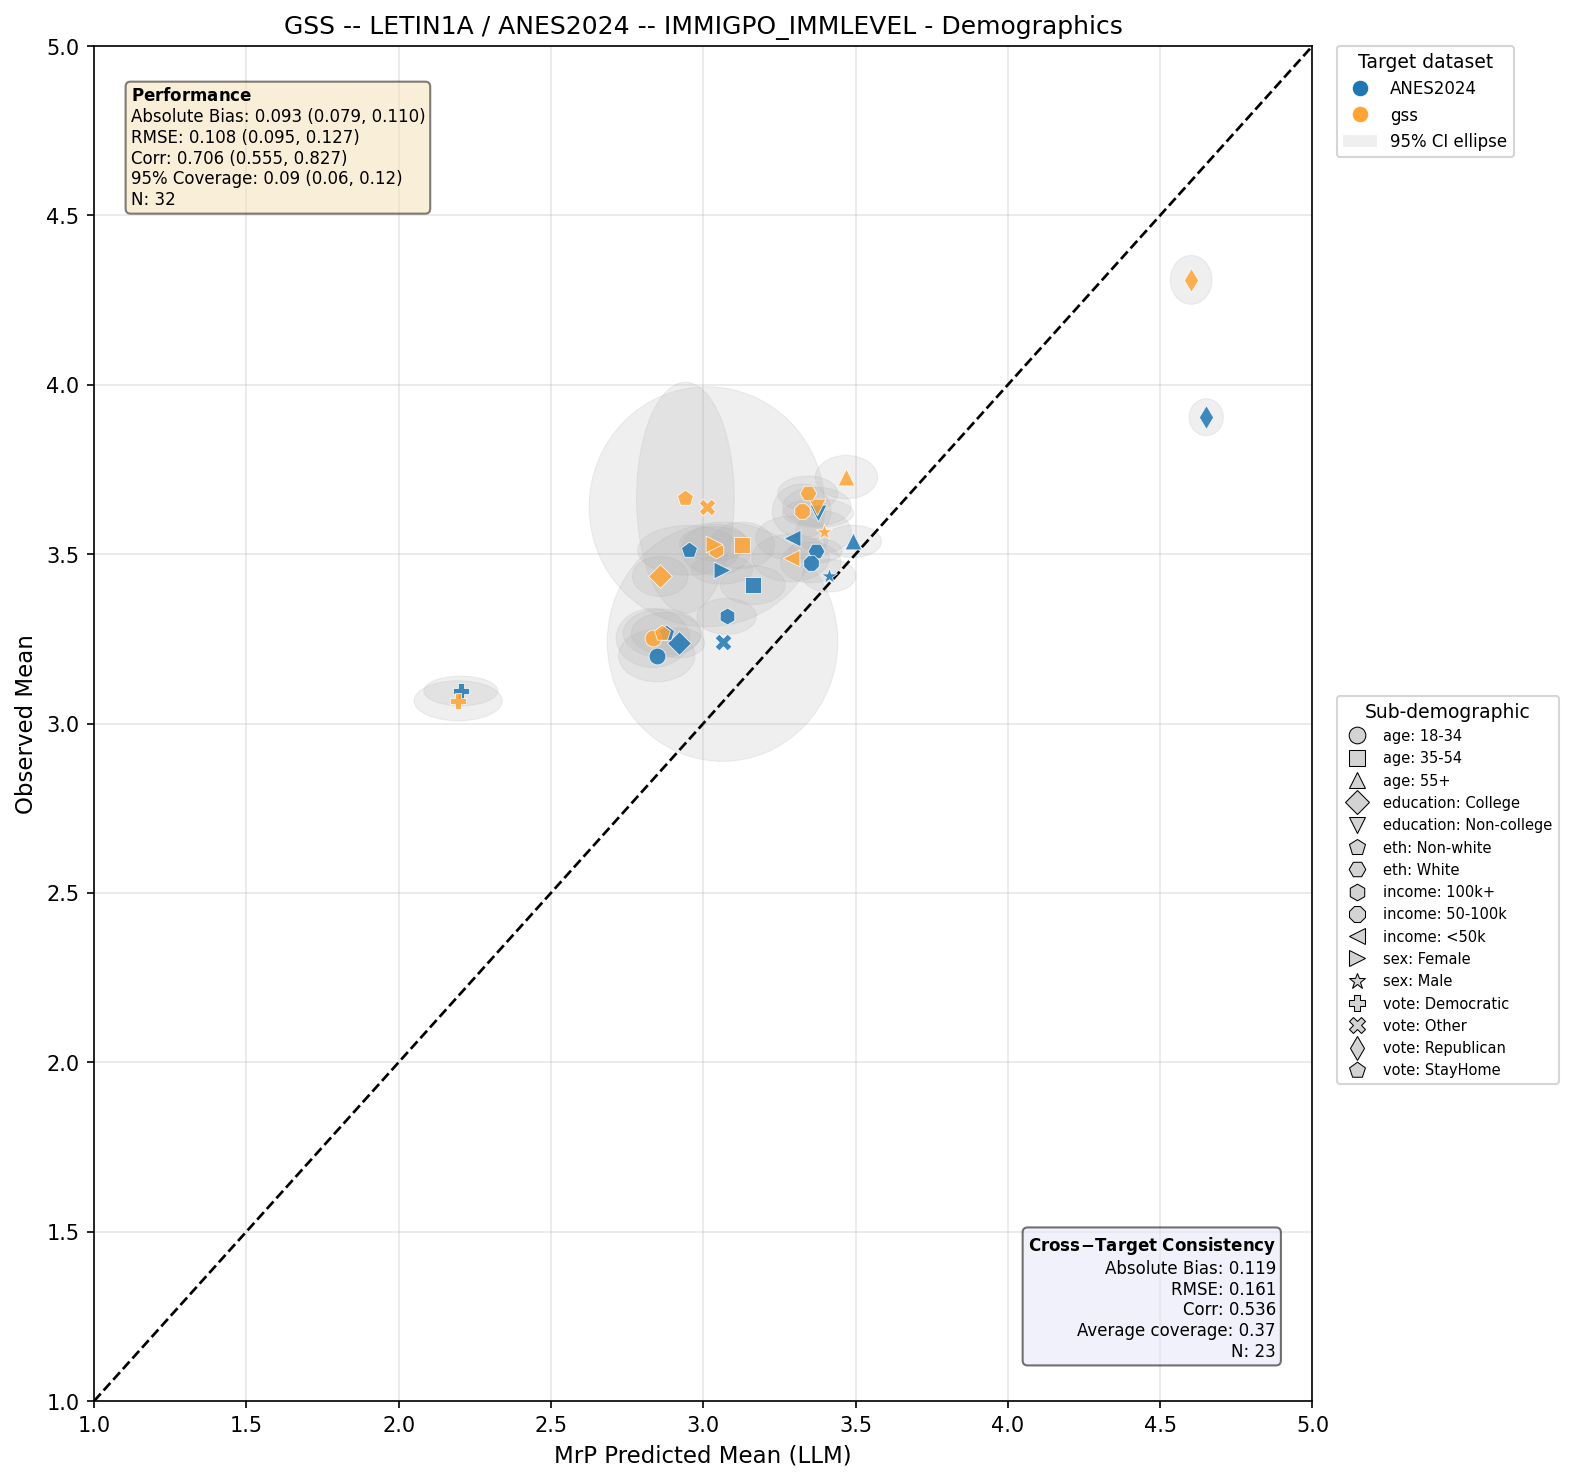

**State plot**

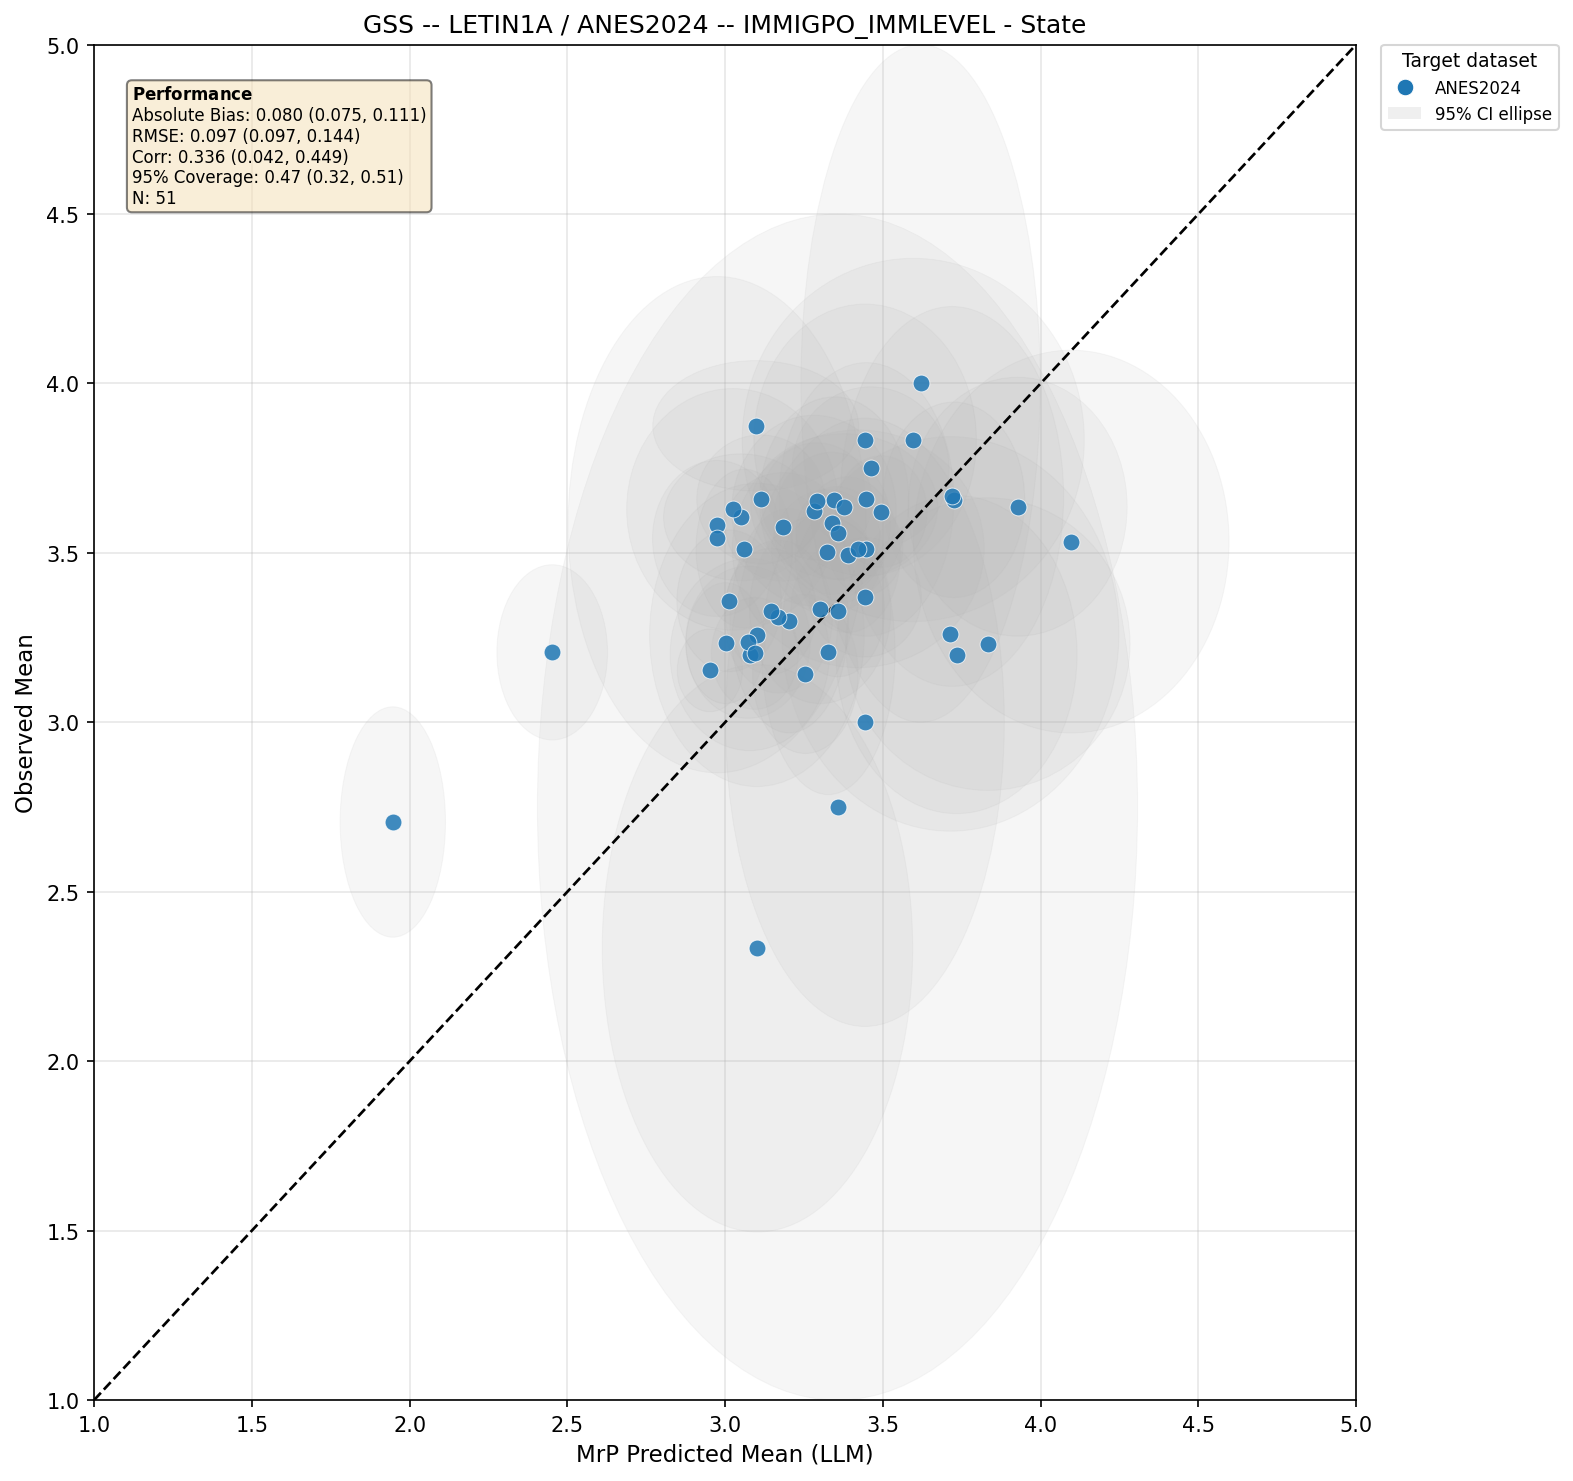

In [23]:
q_id = 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol'

safe_qid = q_id.removesuffix('_Symbol')
plot_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data') / q_id / 'plot'


demo_path = plot_dir / f'{safe_qid}_demographics.png'
state_path = plot_dir / f'{safe_qid}_state.png'

display(Markdown('**Demographics plot**'))
display(Image(filename=str(demo_path)))

display(Markdown('**State plot**'))
display(Image(filename=str(state_path)))
 

**Demographics plot**

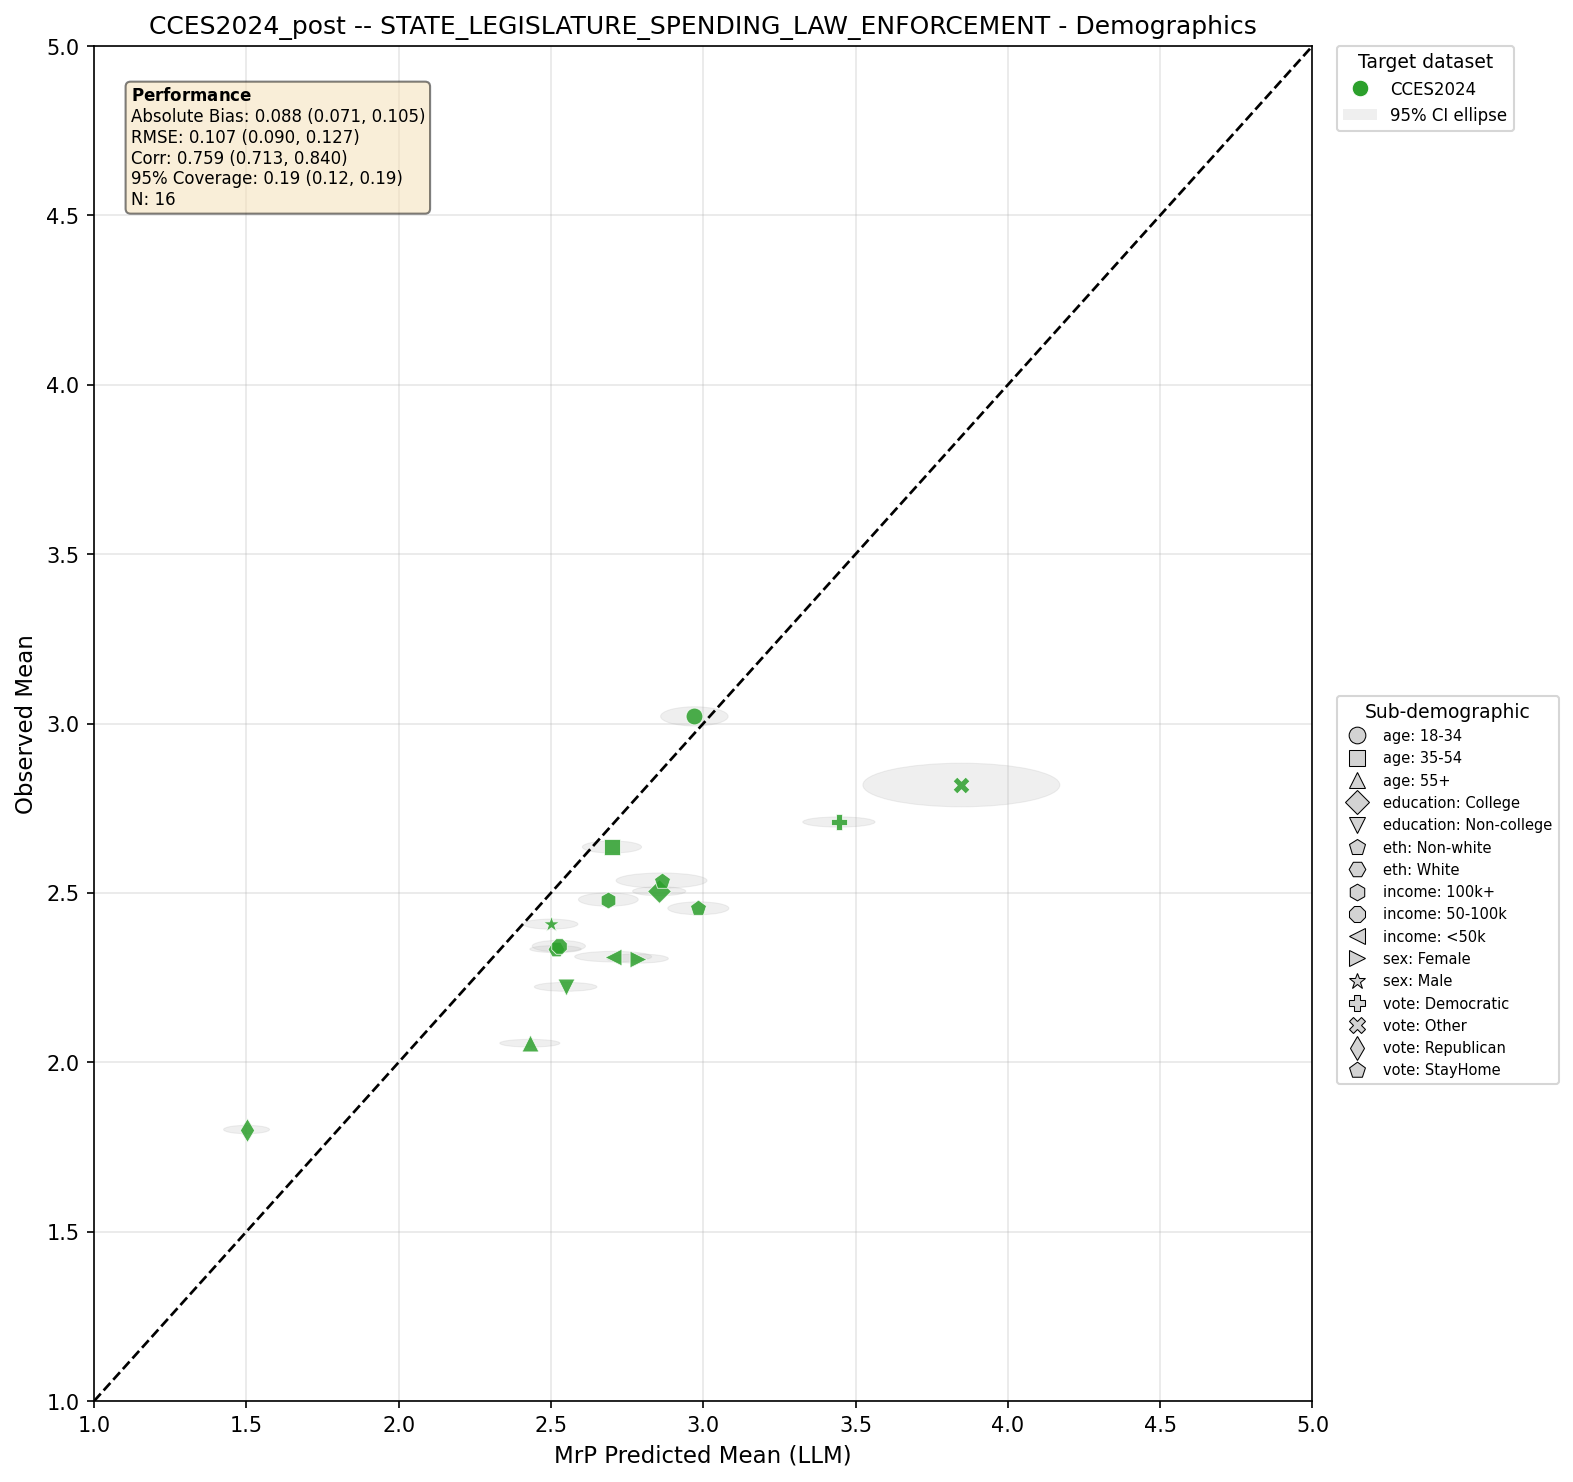

**State plot**

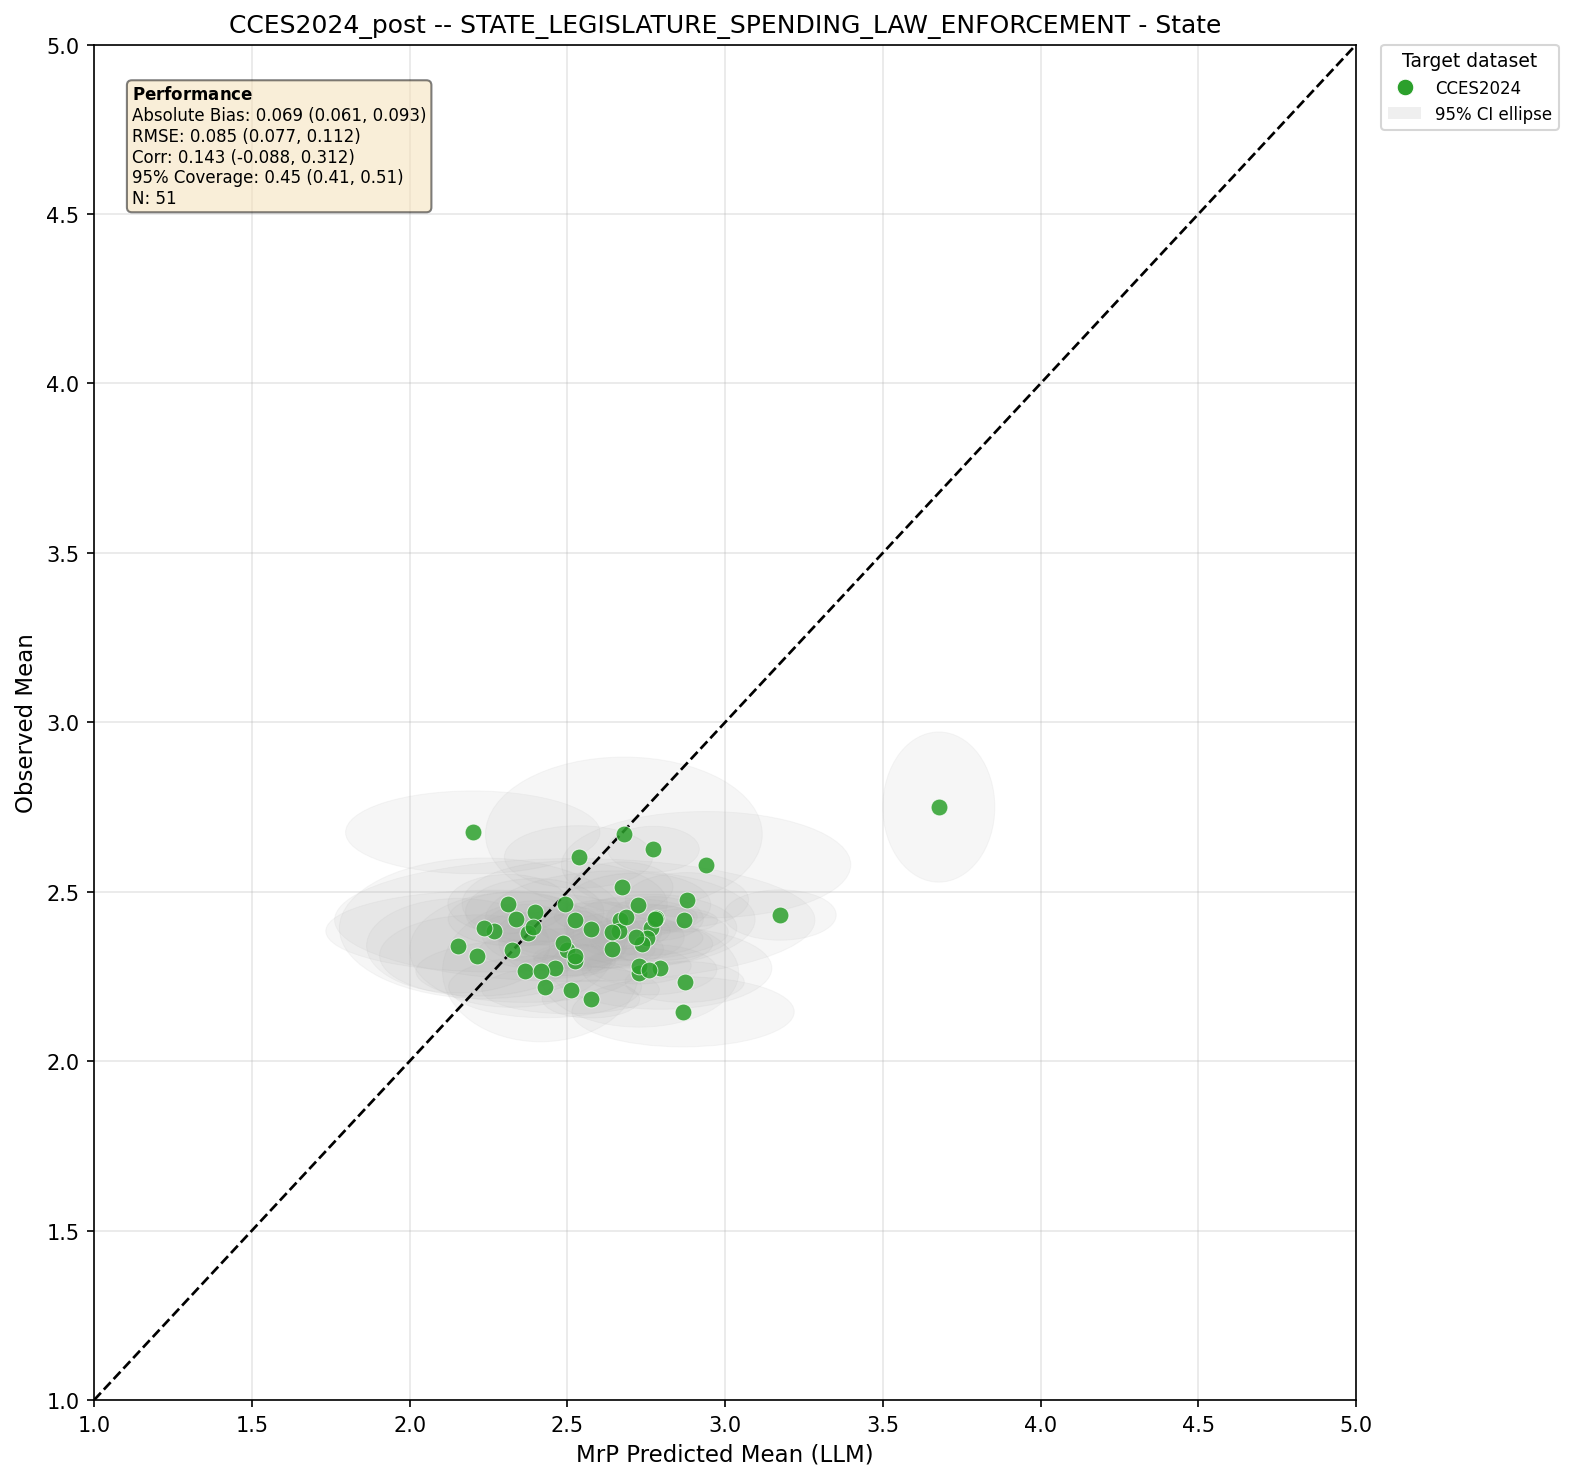

In [24]:
q_id = 'Belief_opinion_on_funding_of_police_departments_Symbol'

safe_qid = q_id.removesuffix('_Symbol')
plot_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data') / q_id / 'plot'

demo_path = plot_dir / f'{safe_qid}_demographics.png'
state_path = plot_dir / f'{safe_qid}_state.png'

display(Markdown('**Demographics plot**'))
display(Image(filename=str(demo_path)))

display(Markdown('**State plot**'))
display(Image(filename=str(state_path)))

## build the overall plots that includes all beleif questions

In [25]:
# Build standardized_plot_df on a 0-1 scale using each question's full category range

# function to infer k (number of categories) for a given question_id from the original df
def infer_k_from_question_id(question_id, source_df):
    col = f"{question_id}_cat"
    if col not in source_df.columns:
        raise KeyError(f"Missing {col} in df; cannot infer k for {question_id}")
    return source_df[col].cat.categories.size

# Find the means and interval bounds from both observed and predicted series
def collect_scale_columns(input_df):
    prefix_cols = [
        c for c in input_df.columns
        if c.startswith('obs_') or c.startswith('pred_')
    ]
    # Standard deviation columns 
    std_cols = [
        c for c in input_df.columns
        if (c.lower().endswith('_sd'))
    ]
    scale_cols = set(prefix_cols + std_cols)
    return [c for c in scale_cols] 

# Standardize observed/predicted means, quantiles and std columns to 0-1
def standardize_plot_df(plot_df_input, source_df_for_k):

    out = deepcopy(plot_df_input)
    scale_cols = collect_scale_columns(out)
    # get the original scale for each belief question
    k_map = {
        qid: infer_k_from_question_id(qid, source_df_for_k)
        for qid in out['question_id'].dropna().unique()
    }
    # use k-1 as denominator
    denom = out['question_id'].map(lambda q: k_map[q] - 1).astype(float)
    if (denom <= 0).any():
        raise ValueError('Invalid denominator k-1 found. Check question category sizes.')

    for c in scale_cols:
        if c.lower().endswith('_sd'):
            out[c] = out[c].astype(float) / denom # for standard deviation columns we divide by k-1 to get the standardized std
        else:
            out[c] = (out[c].astype(float) - 1.0) / denom # for mean and quantile columns we first shift the scale to start at 0 by subtracting 1, then divide by k-1 to standardize to 0-1


    # # Clip numerical drift from floating point.
    # for c in scale_cols:
    #     out[c] = out[c].clip(0.0, 1.0)

    return out

standardized_plot_df = standardize_plot_df(plot_df, df)

standardized_plot_df

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,...,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd,time_window_start,group,n_obs_sources,has_multiple_obs
0,sex,Female,Belief_increase_fossil_fuel_production_Symbol,CCES2024,31991,0.466194,0.463422,0.469149,0.462524,0.470078,...,0.561236,0.510573,0.558084,0.515383,0.552524,0.018414,NaN,NaN,1,False
1,sex,Male,Belief_increase_fossil_fuel_production_Symbol,CCES2024,27454,0.432068,0.429117,0.435072,0.427988,0.435894,...,0.407638,0.353896,0.401598,0.360228,0.394407,0.018410,NaN,NaN,1,False
2,age,18-34,Belief_increase_fossil_fuel_production_Symbol,CCES2024,12132,0.622898,0.618569,0.627483,0.617586,0.628566,...,0.593602,0.529497,0.582162,0.534197,0.576475,0.022565,NaN,NaN,1,False
3,age,35-54,Belief_increase_fossil_fuel_production_Symbol,CCES2024,17387,0.459884,0.456481,0.463203,0.455433,0.464800,...,0.502099,0.446310,0.494868,0.452625,0.490094,0.018457,NaN,NaN,1,False
4,age,55+,Belief_increase_fossil_fuel_production_Symbol,CCES2024,30012,0.378182,0.375076,0.381266,0.374639,0.382271,...,0.423178,0.370810,0.416490,0.377065,0.411515,0.017771,NaN,NaN,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2144,time_window_bin,"[2024-08-25 , 2024-09-08)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,381,0.288714,0.274556,0.304451,0.270962,0.308467,...,0.593686,0.566090,0.590491,0.568519,0.587759,0.009374,2024-08-25 00:00:00+00:00,NaN,1,False
2145,time_window_bin,"[2024-09-08 , 2024-09-22)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,269,0.292441,0.269285,0.309863,0.265604,0.314468,...,0.594740,0.569184,0.591809,0.570992,0.589165,0.009192,2024-09-08 00:00:00+00:00,NaN,1,False
2146,time_window_bin,"[2024-09-22 , 2024-10-06)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,233,0.297568,0.283453,0.314269,0.278270,0.318964,...,0.591691,0.565137,0.588205,0.568286,0.585423,0.009066,2024-09-22 00:00:00+00:00,NaN,1,False
2147,time_window_bin,"[2024-10-06 , 2024-10-20)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,278,0.309353,0.290878,0.323987,0.287091,0.329735,...,0.593649,0.566205,0.590751,0.568052,0.588217,0.009771,2024-10-06 00:00:00+00:00,NaN,1,False


In [26]:
plot_df['grouping_var'].unique()

array(['sex', 'age', 'income', 'eth', 'education', 'vote', 'state',
       'time_window_bin'], dtype=object)

In [27]:
# standardize draw level input
def standardize_draw_level_inputs(llm_draws_df_input, target_boot_df_input, source_df_for_k):
    """
    Standardize draw-level inputs to 0-1 using per-question scale 1..k.
    - posterior draw columns in llm_draws_df: (x - 1) / (k - 1)
    - target bootstrap means in target_boot_df['obs_boot_mean']: (x - 1) / (k - 1)
    """
    key_cols = ['grouping_var', 'category', 'question_id', 'benchmark']

    llm_draws_std = llm_draws_df_input.copy()
    target_boot_std = target_boot_df_input.copy()

    qids = pd.Index(
        llm_draws_std['question_id'].dropna().astype(str).unique()
    ).union(
        target_boot_std['question_id'].dropna().astype(str).unique()
    )

    k_map = {qid: infer_k_from_question_id(qid, source_df_for_k) for qid in qids}


    denom_pred = llm_draws_std['question_id'].astype(str).map(lambda q: float(k_map[q] - 1))
    denom_targ = target_boot_std['question_id'].astype(str).map(lambda q: float(k_map[q] - 1))

    if (denom_pred <= 0).any() or (denom_targ <= 0).any():
        raise ValueError('Invalid denominator k-1 while standardizing draw-level inputs.')

    meta_cols = set(key_cols + ['draw_idx'])
    # non_draw_numeric = {
    #     'pred_mean', 'pred_lower_68', 'pred_upper_68',
    #     'pred_lower_80', 'pred_upper_80',
    #     'pred_lower_90', 'pred_upper_90',
    #     'pred_lower_95', 'pred_upper_95', 'n'
    # }
    draw_cols = [
        c for c in llm_draws_std.columns
        if c not in meta_cols
        # and c not in non_draw_numeric
        # and pd.api.types.is_numeric_dtype(llm_draws_std[c])
    ]

    # Standardize posterior draws and interval summaries if present.
    for c in draw_cols:
        llm_draws_std[c] = (llm_draws_std[c].astype(float) - 1.0) / denom_pred

    # for c in [
    #     'pred_mean', 'pred_lower_68', 'pred_upper_68',
    #     'pred_lower_80', 'pred_upper_80',
    #     'pred_lower_90', 'pred_upper_90',
    #     'pred_lower_95', 'pred_upper_95'
    # ]:
    #     if c in llm_draws_std.columns:
    #         llm_draws_std[c] = (llm_draws_std[c].astype(float) - 1.0) / denom_pred

    # Standardize target bootstrap means.
    target_boot_std['obs_boot_mean'] = (target_boot_std['obs_boot_mean'].astype(float) - 1.0) / denom_targ

    # # Clip numerical drift.
    # for c in draw_cols:
    #     llm_draws_std[c] = llm_draws_std[c].clip(0.0, 1.0)
    # for c in ['pred_mean', 'pred_lower_95', 'pred_upper_95']:
    #     if c in llm_draws_std.columns:
    #         llm_draws_std[c] = llm_draws_std[c].clip(0.0, 1.0)
    # target_boot_std['obs_boot_mean'] = target_boot_std['obs_boot_mean'].clip(0.0, 1.0)

    return llm_draws_std, target_boot_std

In [28]:
# build the overall plot for demo + state

# Standardize all inputs
llm_draws_std, target_boot_std = standardize_draw_level_inputs(
    llm_draws_df, target_boot_df, df
)
demo_all = standardized_plot_df[~standardized_plot_df['grouping_var'].isin(['state', 'time_window_bin'])].copy()
state_all = standardized_plot_df[standardized_plot_df['grouping_var'] == 'state'].copy()

key_cols = ['grouping_var', 'category', 'question_id', 'benchmark']
demo_keys = demo_all[key_cols].drop_duplicates()
state_keys = state_all[key_cols].drop_duplicates()

llm_draws_demo = llm_draws_std.merge(demo_keys, on=key_cols, how='inner')
target_boot_demo = target_boot_std.merge(demo_keys, on=key_cols, how='inner')
llm_draws_state = llm_draws_std.merge(state_keys, on=key_cols, how='inner')
target_boot_state = target_boot_std.merge(state_keys, on=key_cols, how='inner')

# compute_metrics
demo_perf = compute_metrics(
    demo_all,
    llm_draws_df=llm_draws_demo,
    target_boot_df=target_boot_demo,
    y_range = 1
)
state_perf = compute_metrics(
    state_all,
    llm_draws_df=llm_draws_state,
    target_boot_df=target_boot_state,
    y_range = 1
)

# Demographic pooled ceiling metrics
demo_ceiling_pairwise = compute_obs_pairwise(demo_all)
demo_ceiling = compute_obs_pairwise_metrics(demo_ceiling_pairwise, ci_level=95)

# Save paths.
out_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_belief_plots')
out_dir.mkdir(parents=True, exist_ok=True)
demo_out = out_dir / 'all_beliefs_demographics.png'
state_out = out_dir / 'all_beliefs_state.png'

# Plot + save demographics using the same per-question plotting function.
fig_demo, ax_demo = plt.subplots(1, 1, figsize=(14, 10))
plot_scatter_with_uncertainty_ellipses(
    ax_demo,
    demo_all,
    metrics=demo_perf,
    ci_level=95,
    question_id=None,
    benchmark=None,
    ceiling_metrics=demo_ceiling,
    state=False,
    standardized_axis=True
)
fig_demo.tight_layout(rect=[0, 0, 0.78, 1])
fig_demo.savefig(demo_out, dpi=200, bbox_inches='tight')
plt.close(fig_demo)

# Plot + save state using the same per-question plotting function.
fig_state, ax_state = plt.subplots(1, 1, figsize=(14, 10))
plot_scatter_with_uncertainty_ellipses(
    ax_state,
    state_all,
    metrics=state_perf,
    ci_level=95,
    question_id=None,
    benchmark=None,
    ceiling_metrics=None,
    state=True,
    standardized_axis=True
)
fig_state.tight_layout(rect=[0, 0, 0.78, 1])
fig_state.savefig(state_out, dpi=200, bbox_inches='tight')
plt.close(fig_state)

print('Saved:', demo_out)
print('Saved:', state_out)
print('Demographic pooled performance:', demo_perf)
print('Demographic pooled ceiling:', demo_ceiling)
print('State pooled performance:', state_perf)

Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_belief_plots/all_beliefs_demographics.png
Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_belief_plots/all_beliefs_state.png
Demographic pooled performance: {'bias_mean': 0.14580505989422113, 'bias_ci': (0.14346589211078414, 0.15072214086198485), 'rmse_mean': 0.18482067520519727, 'rmse_ci': (0.18119380782910255, 0.1915801899171368), 'corr_mean': 0.5495507129677919, 'corr_ci': (0.5277444577406033, 0.5650607047313954), 'coverage_mean': 0.15705128205128205, 'coverage_ci': (0.1429088194763436, 0.16553504977987438), 'n_cells': 624}
Demographic pooled ceiling: {'bias_mean': np.float64(0.07434052826832208), 'rmse_mean': np.float64(0.16049299078718904), 'corr_mean': np.float64(0.8076487071294944), 'cov_sym_mean': np.float64(0.2784090909090909), 'n': 176}
State pooled performance: {'bias_mean': 0.14773096213502482, 'bias_ci': (0.15226355315769532, 0.16080092120752795), 'rmse_mean': 0.19

**All beliefs: demographics plot**

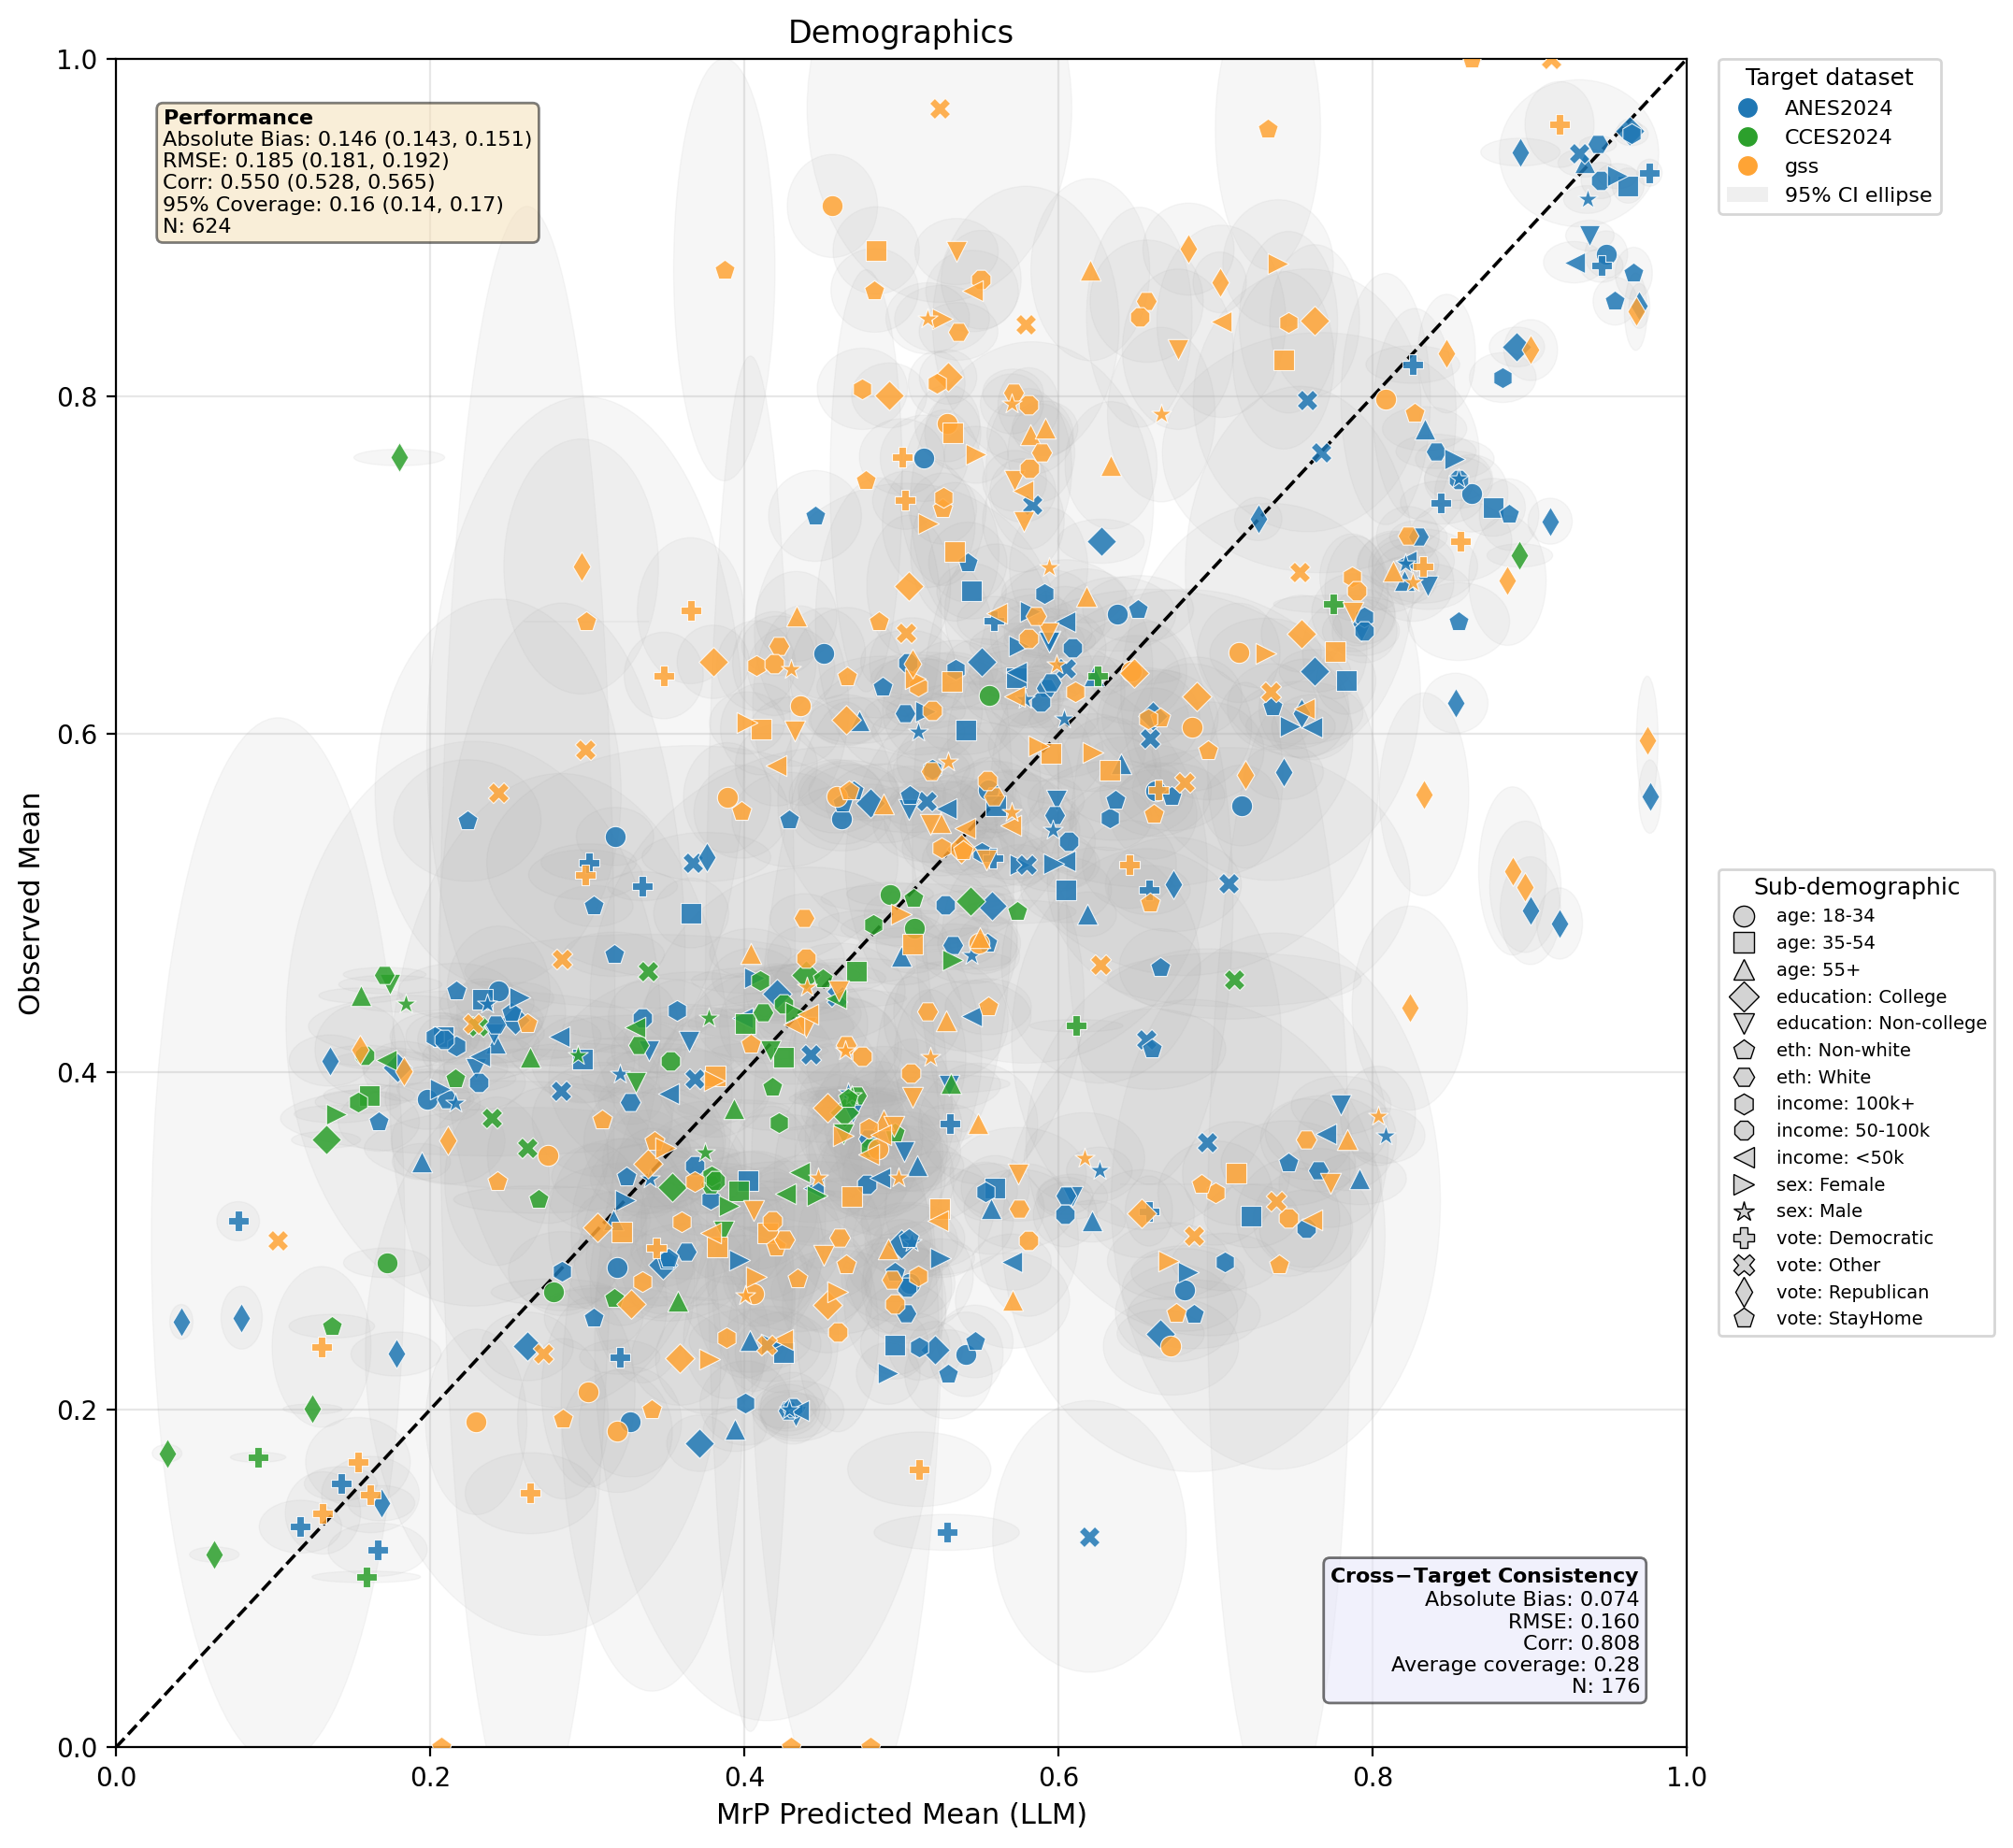

**All beliefs: state plot**

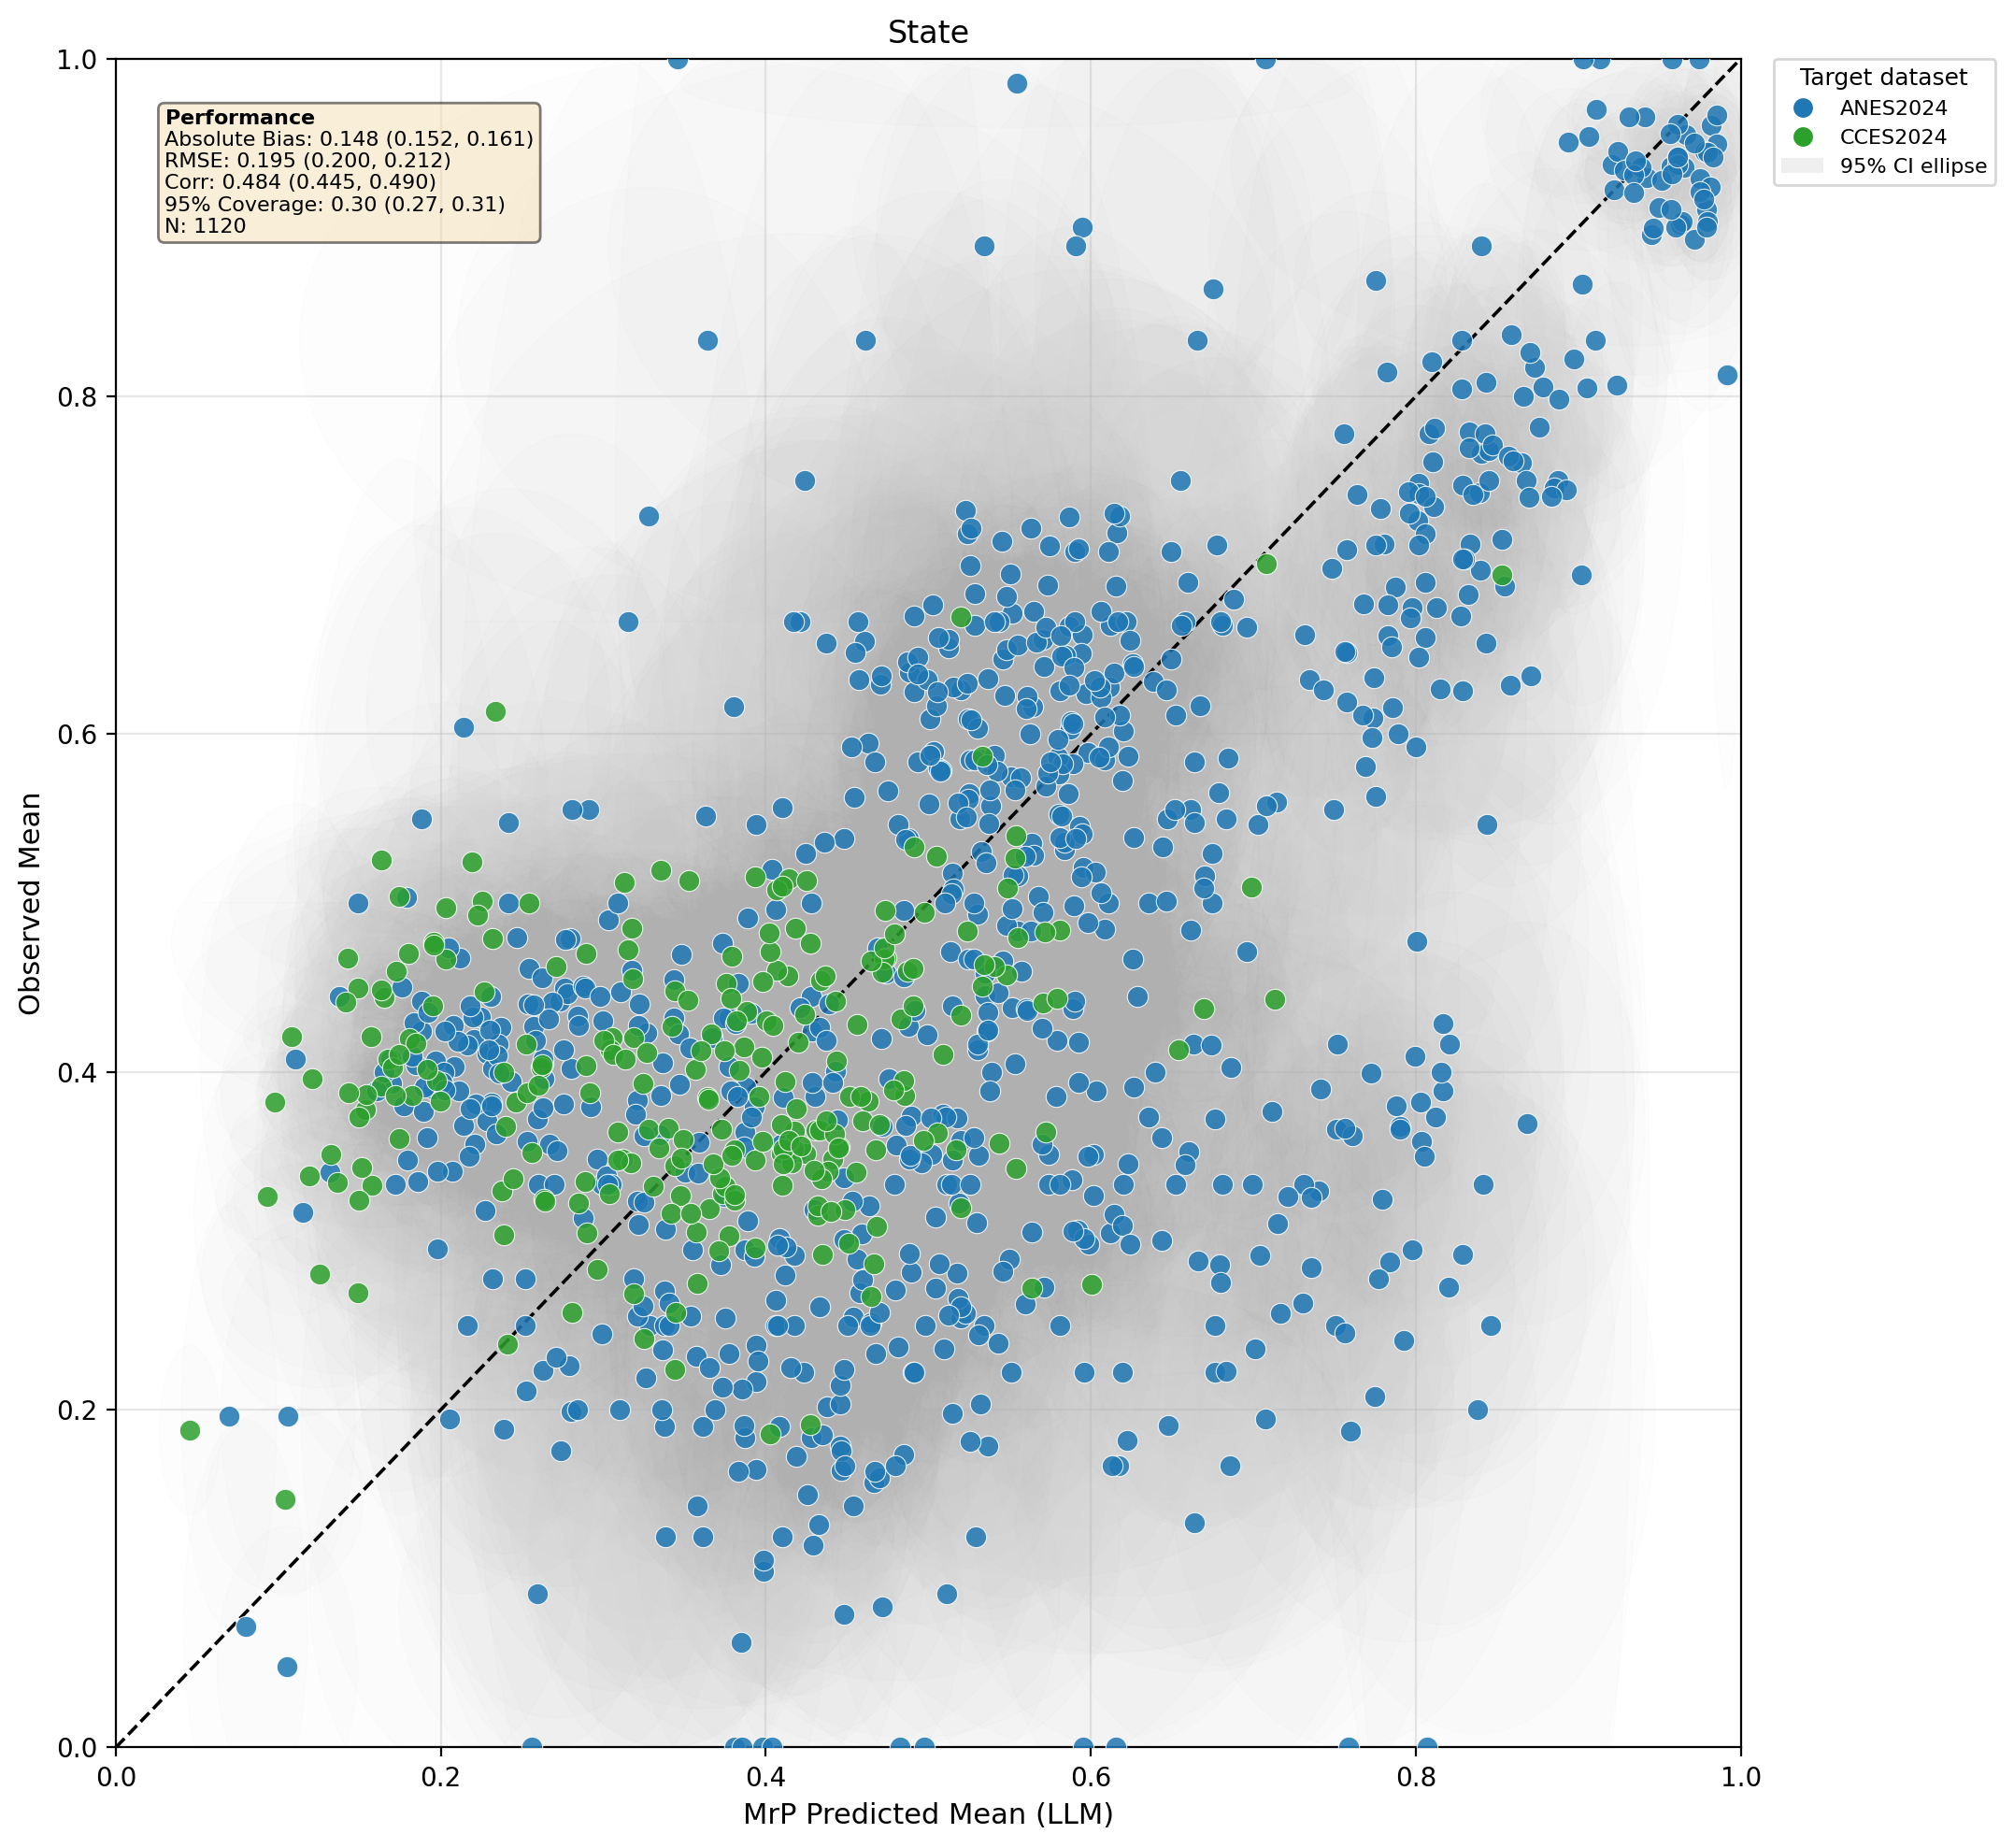

In [29]:
# show all belief plots
plot_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_belief_plots')
demo_path = plot_dir / 'all_beliefs_demographics.png'
state_path = plot_dir / 'all_beliefs_state.png'

display(Markdown('**All beliefs: demographics plot**'))
display(Image(filename=str(demo_path)))

display(Markdown('**All beliefs: state plot**'))
display(Image(filename=str(state_path)))

## build national level plot

In [30]:
# National-level plot across all beliefs 

national_all = standardized_plot_df[standardized_plot_df['grouping_var'] == 'time_window_bin'].copy()
if national_all.empty:
    raise ValueError('No national time_window_bin rows found in standardized_plot_df.')

key_cols = ['grouping_var', 'category', 'question_id', 'benchmark']
national_keys = national_all[key_cols].drop_duplicates()
llm_draws_national = llm_draws_std.merge(national_keys, on=key_cols, how='inner')
target_boot_national = target_boot_std.merge(national_keys, on=key_cols, how='inner')

national_perf = compute_metrics(
    national_all,
    llm_draws_df=llm_draws_national,
    target_boot_df=target_boot_national,
    y_range = 1
 )
national_ceiling_pairwise = compute_obs_pairwise(national_all)
national_ceiling = compute_obs_pairwise_metrics(national_ceiling_pairwise, ci_level=95)

out_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_plots')
out_dir.mkdir(parents=True, exist_ok=True)
national_out = out_dir / 'national_time_window_scatter.png'

fig_nat, ax_nat = plt.subplots(1, 1, figsize=(14, 10))
plot_scatter_with_uncertainty_ellipses(
    ax_nat,
    national_all,
    metrics=national_perf,
    ci_level=95,
    question_id=None,
    benchmark=None,
    ceiling_metrics=national_ceiling,
    state=None,
    national=True,
    standardized_axis=True
 )
fig_nat.tight_layout(rect=[0, 0, 0.78, 1])
fig_nat.savefig(national_out, dpi=200, bbox_inches='tight')
plt.close(fig_nat)

print('Saved:', national_out)
print('National pooled performance:', national_perf)
print('National pooled ceiling:', national_ceiling)

Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_plots/national_time_window_scatter.png
National pooled performance: {'bias_mean': 0.14985116614796679, 'bias_ci': (0.14958405282956336, 0.15798017071473722), 'rmse_mean': 0.18899643157430873, 'rmse_ci': (0.18984876716996793, 0.20239178819137174), 'corr_mean': 0.4660808325694572, 'corr_ci': (0.4323891094970209, 0.49196150563479074), 'coverage_mean': 0.11604938271604938, 'coverage_ci': (0.08007025515984434, 0.12864136413641364), 'n_cells': 405}
National pooled ceiling: {'bias_mean': np.float64(0.09638659905517206), 'rmse_mean': np.float64(0.19048634707137818), 'corr_mean': np.float64(0.7193940515858326), 'cov_sym_mean': np.float64(0.3698630136986301), 'n': 73}


**National time window plot**

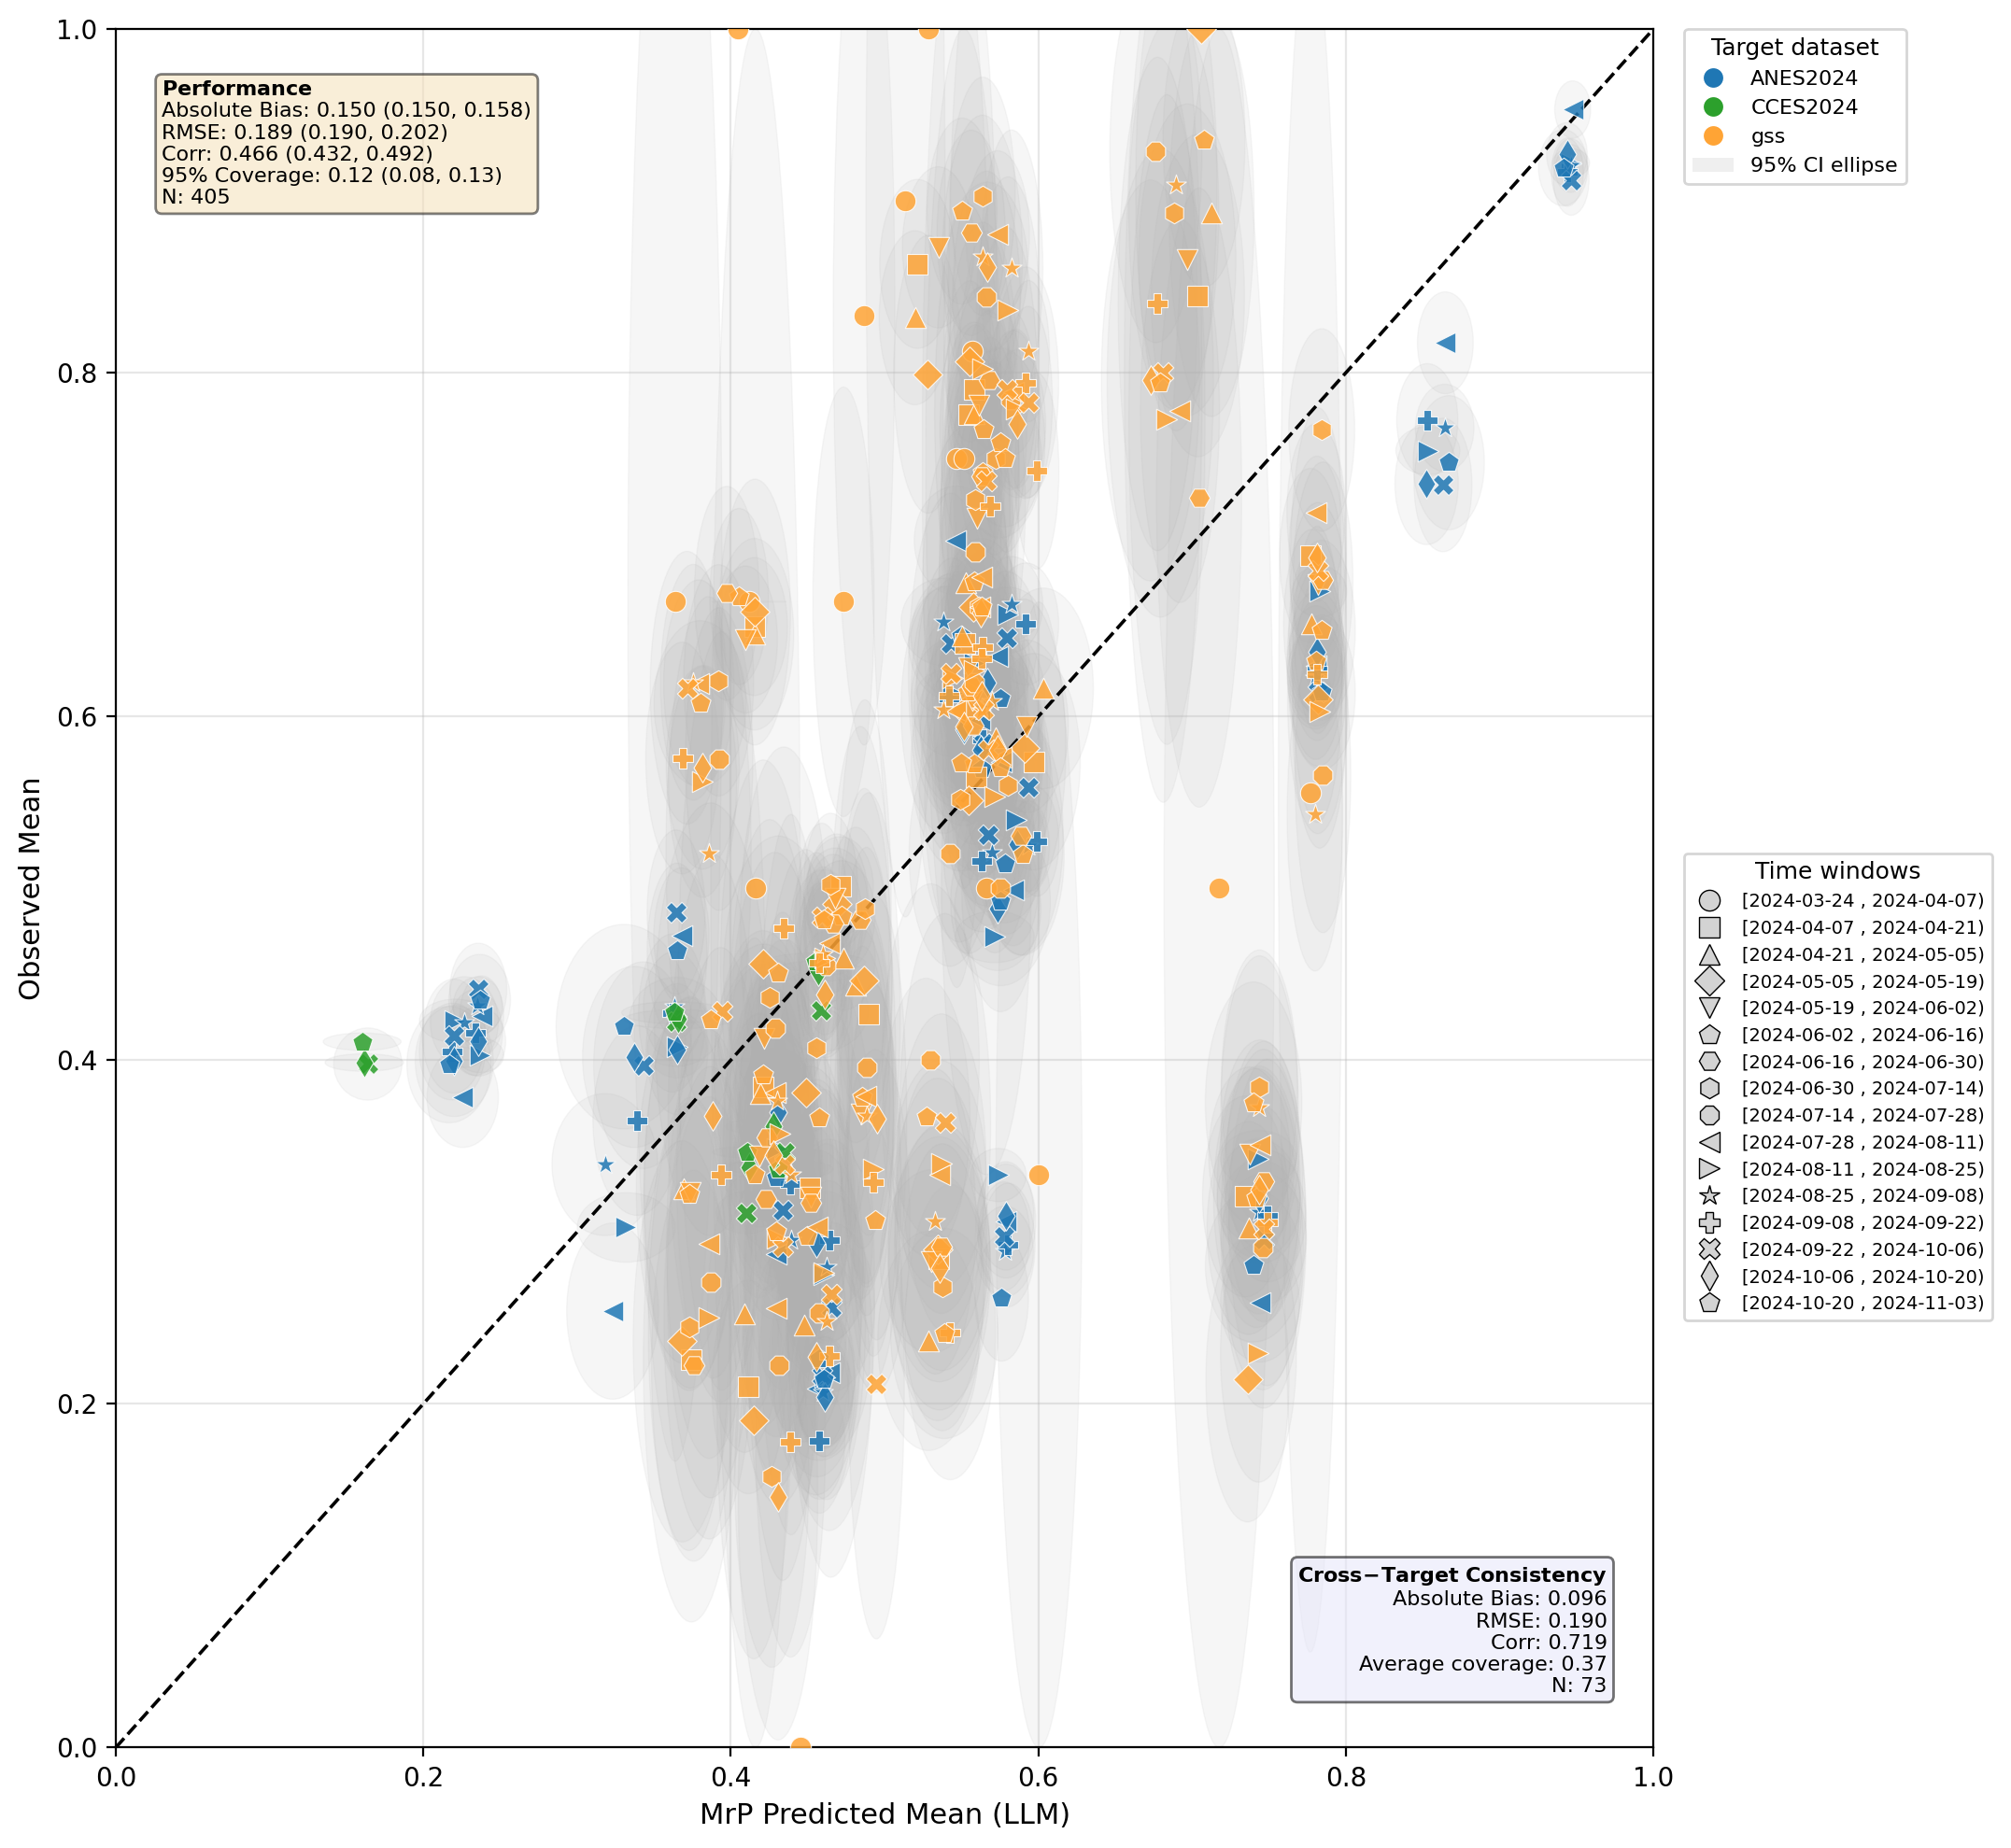

In [31]:
# show national plot
plot_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_plots')
national_path = plot_dir / 'national_time_window_scatter.png'
display(Markdown('**National time window plot**'))
display(Image(filename=str(national_path)))

# make a plot for the overtime trend for each belief
8x4 one page of plot, each plot has the overtime line, confidence interval around it and the over time observe line, top left correlation with intervals, no moving-average, national level


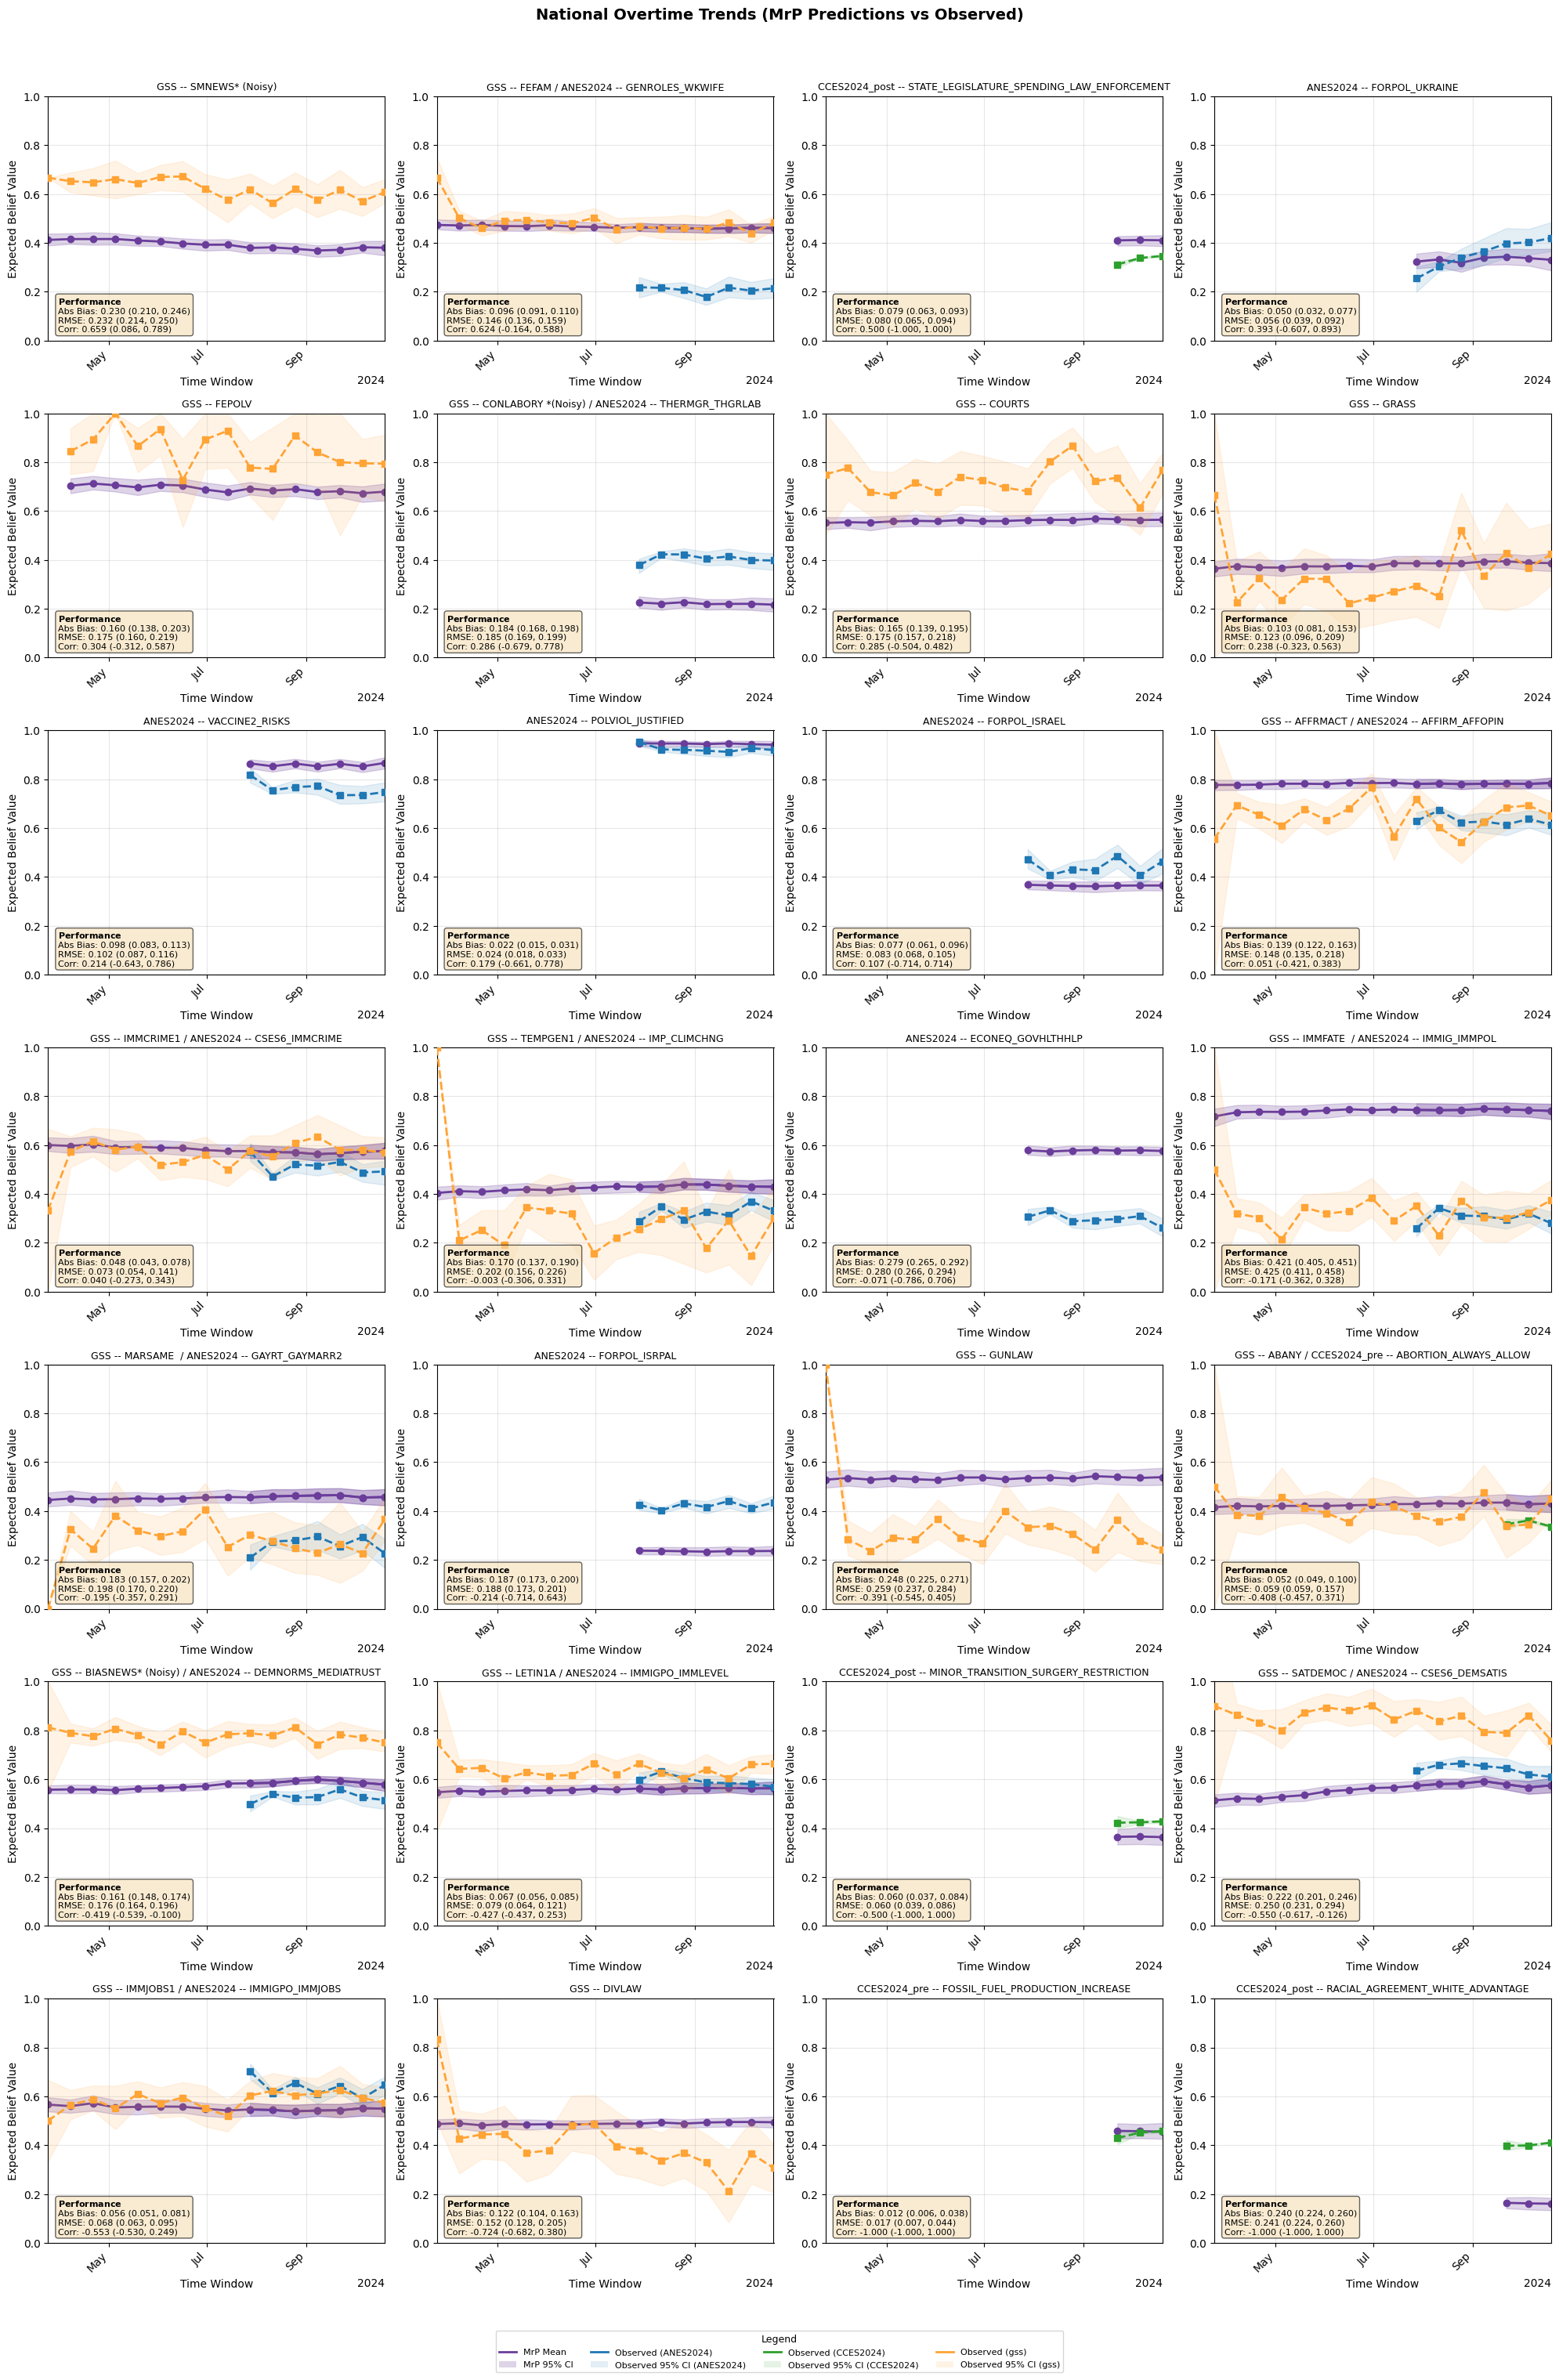

[PosixPath('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_plots/national_overtime_trend.png')]

In [32]:
# National overtime plots: 7x4 grid (one plot per belief)

# return a list of unique benchmarks for a given question
def collect_benchmarks_for_question(national_df, question_id):
   return (
       national_df[
           national_df['question_id'].astype(str) == str(question_id)
       ]
       ['benchmark'].dropna().unique().tolist()
   )


def build_national_series_by_benchmark(national_df, question_id):
   benches = collect_benchmarks_for_question(national_df, question_id)
   series_map = {}
   for bench in benches:
       subset = national_df[
           (national_df['question_id'].astype(str) == str(question_id))
           & (national_df['benchmark'] == bench)
       ].copy()
       if subset.empty:
           continue
       subset['time_window_start'] = subset['category'].map(parse_time_window_start)
       subset['time_dt'] = pd.to_datetime(subset['time_window_start'])
       subset = subset.sort_values('time_dt')
       series_map[str(bench)] = subset
   return series_map


def compute_question_metrics(question_id, plot_df_input, llm_draws_input, target_boot_input):
   work = plot_df_input[
       plot_df_input['question_id'].astype(str) == str(question_id)
   ].copy()
   if work.empty:
       return None

   key_cols = ['grouping_var', 'category', 'question_id', 'benchmark']
   keys = work[key_cols].drop_duplicates()
   llm_draws_sub = llm_draws_input.merge(keys, on=key_cols, how='inner')
   target_boot_sub = target_boot_input.merge(keys, on=key_cols, how='inner')
   if llm_draws_sub.empty or target_boot_sub.empty:
       return None

   return compute_metrics(
       work,
       llm_draws_df=llm_draws_sub,
       target_boot_df=target_boot_sub,
       y_range = 1
   )


def plot_national_overtime_grid(
   national_df,
   llm_draws_input,
   target_boot_input,
   title_mapper=None,
   nrows=7,
   ncols=4,
   save_dir=None
):
    questions = (
       national_df['question_id']
       .dropna()
       .astype(str)
       .unique()
   )
    questions = sorted(questions)

    metrics_by_qid = {}
    for qid in questions:
       metrics = compute_question_metrics(
           qid, national_df, llm_draws_input, target_boot_input
       )
       metrics_by_qid[qid] = metrics

    corr_order = []
    for qid in questions:
       metrics = metrics_by_qid.get(qid)
       corr_val = metrics['corr_mean'] if metrics is not None else np.nan
       corr_order.append((corr_val, qid))
    corr_order.sort(key=lambda item: (np.isnan(item[0]), item[0]),reverse=True)
    questions = [qid for _, qid in corr_order]

    dataset_color_map = {
       'ANES2024': '#1f77b4',
       'CCES2024': '#2ca02c',
       'gss': '#ffa435'
   }
    mrp_color = '#6a3d9a'

   # Keep time axes consistent across subplots.
    time_source = national_df.copy()
    time_source['time_window_start'] = time_source['category'].map(parse_time_window_start)
    time_source['time_dt'] = pd.to_datetime(time_source['time_window_start'])
    time_min = time_source['time_dt'].min() 
    time_max = time_source['time_dt'].max() 
    date_locator = mdates.AutoDateLocator(minticks=3, maxticks=4)
    date_formatter = mdates.ConciseDateFormatter(date_locator)

    save_paths = []

    fig, axes = plt.subplots(nrows, ncols, figsize=(20, 32), squeeze=False)
    axes = axes.flatten()

    page_benchmarks = set()

    for ax_idx, qid in enumerate(questions):
        ax = axes[ax_idx]
        series_map = build_national_series_by_benchmark(national_df, qid)

        benchmarks = sorted(series_map.keys())
        page_benchmarks.update(benchmarks)

        # Plot each benchmark: MrP line (fixed color) + CI and observed line + CI (dataset color).
        for bench in benchmarks:
            series_df = series_map[bench]
            obs_color = dataset_color_map.get(bench, '#7f7f7f')

            ax.plot(
                series_df['time_dt'], series_df['pred_mean'],
                marker='o', linewidth=2.0, color=mrp_color,
                label='MrP Mean'
            )
            ax.fill_between(
                series_df['time_dt'],
                series_df['pred_lower_95'],
                series_df['pred_upper_95'],
                alpha=0.22, color=mrp_color, label='MrP 95% CI'
            )

            ax.plot(
                series_df['time_dt'], series_df['obs_mean'],
                marker='s', linewidth=2.0, color=obs_color, linestyle='--',
                label=f'Observed Mean ({bench})', zorder=3
            )
            ax.fill_between(
                series_df['time_dt'],
                series_df['obs_lower_95'],
                series_df['obs_upper_95'],
                alpha=0.12, color=obs_color, label=f'Observed 95% CI ({bench})', zorder=2
            )

        # Metrics box across all benchmarks/time bins for this question.
        metrics = metrics_by_qid.get(qid)
        if metrics is not None:
            textstr = (
                f'$\\mathbf{{Performance}}$\n'
                f'Abs Bias: {metrics["bias_mean"]:.3f} '
                f'({metrics["bias_ci"][0]:.3f}, {metrics["bias_ci"][1]:.3f})\n'
                f'RMSE: {metrics["rmse_mean"]:.3f} '
                f'({metrics["rmse_ci"][0]:.3f}, {metrics["rmse_ci"][1]:.3f})\n'
                f'Corr: {metrics["corr_mean"]:.3f} '
                f'({metrics["corr_ci"][0]:.3f}, {metrics["corr_ci"][1]:.3f})'
            )
        else:
            textstr = f'$\\mathbf{{Performance}}$\nNo matched draws'
        ax.text(
            0.03, 0.03, textstr,
            transform=ax.transAxes,
            fontsize=8,
            va='bottom', ha='left',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.6)
        )

        # Titles.
        title = str(qid)
        if title_mapper is not None:
            match = title_mapper.loc[
                title_mapper['cleaned_feature'].astype(str).str.strip() == str(qid).strip(),
                'title'
            ]
            if not match.empty and pd.notna(match.iloc[0]):
                title = str(match.iloc[0])
        ax.set_title(title, fontsize=9)

        ax.set_xlabel('Time Window')
        ax.set_ylabel('Expected Belief Value')
        ax.set_ylim([0.0, 1.0])
        ax.set_xlim([time_min, time_max])
        ax.xaxis.set_major_locator(date_locator)
        ax.xaxis.set_major_formatter(date_formatter)
        ax.grid(True, alpha=0.3)
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

    # # Hide unused axes.
    # for ax in axes[len(page_qids):]:
    #     ax.axis('off')

    legend_handles = [
        Line2D([0], [0], color=mrp_color, lw=2, label='MrP Mean'),
        Patch(facecolor=mrp_color, alpha=0.22, label='MrP 95% CI'),
    ]
    for bench in sorted(page_benchmarks):
        legend_handles.append(
            Line2D([0], [0], color=dataset_color_map.get(bench, '#7f7f7f'), lw=2, label=f'Observed ({bench})')
        )
        legend_handles.append(
            Patch(facecolor=dataset_color_map.get(bench, '#7f7f7f'), alpha=0.12, label=f'Observed 95% CI ({bench})')
        )

    fig.legend(
        handles=legend_handles,
        title='Legend',
        fontsize=8,
        title_fontsize=9,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.05),
        ncol=len(legend_handles) // 2,
        frameon=True
    )

    fig.tight_layout(rect=[0, 0.08, 1, 0.97])
    fig.suptitle(
        'National Overtime Trends (MrP Predictions vs Observed)',
        fontsize=14,
        fontweight='bold',
        y=0.995
    )

    out_path = None
    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        out_path = save_dir / f'national_overtime_trend.png'
        fig.savefig(out_path, dpi=200, bbox_inches='tight')
    save_paths.append(out_path)
    plt.show()
    
    return save_paths

 # run the plot 
plot_national_overtime_grid(
   national_df=national_all,
   llm_draws_input=llm_draws_national,
   target_boot_input=target_boot_national,
   title_mapper=title_mapper,
   nrows=7,
   ncols=4,
   save_dir='/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_plots'
)

In [33]:
national_all

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,...,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd,time_window_start,group,n_obs_sources,has_multiple_obs
67,time_window_bin,"[2024-09-22 , 2024-10-06)",Belief_increase_fossil_fuel_production_Symbol,CCES2024,1662,0.429001,0.416388,0.439891,0.411996,0.444629,...,0.483625,0.438626,0.477853,0.443495,0.473334,0.015535,2024-09-22 00:00:00+00:00,national,1,False
68,time_window_bin,"[2024-10-06 , 2024-10-20)",Belief_increase_fossil_fuel_production_Symbol,CCES2024,29252,0.451867,0.448732,0.454844,0.447642,0.455671,...,0.482636,0.437201,0.476932,0.442345,0.473607,0.015471,2024-10-06 00:00:00+00:00,national,1,False
69,time_window_bin,"[2024-10-20 , 2024-11-03)",Belief_increase_fossil_fuel_production_Symbol,CCES2024,29075,0.457059,0.454234,0.460333,0.453626,0.460944,...,0.481332,0.434973,0.476890,0.438331,0.473391,0.017143,2024-10-20 00:00:00+00:00,national,1,False
137,time_window_bin,"[2024-09-22 , 2024-10-06)",Belief_opinion_on_funding_of_police_department...,CCES2024,1518,0.311265,0.305056,0.318245,0.303436,0.319481,...,0.425455,0.398047,0.421989,0.400867,0.419677,0.009921,2024-09-22 00:00:00+00:00,NaN,1,False
138,time_window_bin,"[2024-10-06 , 2024-10-20)",Belief_opinion_on_funding_of_police_department...,CCES2024,25429,0.337784,0.335704,0.339322,0.335232,0.340036,...,0.427289,0.397883,0.425861,0.402254,0.422955,0.010520,2024-10-06 00:00:00+00:00,NaN,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2144,time_window_bin,"[2024-08-25 , 2024-09-08)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,381,0.288714,0.274556,0.304451,0.270962,0.308467,...,0.593686,0.566090,0.590491,0.568519,0.587759,0.009374,2024-08-25 00:00:00+00:00,NaN,1,False
2145,time_window_bin,"[2024-09-08 , 2024-09-22)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,269,0.292441,0.269285,0.309863,0.265604,0.314468,...,0.594740,0.569184,0.591809,0.570992,0.589165,0.009192,2024-09-08 00:00:00+00:00,NaN,1,False
2146,time_window_bin,"[2024-09-22 , 2024-10-06)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,233,0.297568,0.283453,0.314269,0.278270,0.318964,...,0.591691,0.565137,0.588205,0.568286,0.585423,0.009066,2024-09-22 00:00:00+00:00,NaN,1,False
2147,time_window_bin,"[2024-10-06 , 2024-10-20)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,278,0.309353,0.290878,0.323987,0.287091,0.329735,...,0.593649,0.566205,0.590751,0.568052,0.588217,0.009771,2024-10-06 00:00:00+00:00,NaN,1,False


In [34]:
standardized_plot_df

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,...,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd,time_window_start,group,n_obs_sources,has_multiple_obs
0,sex,Female,Belief_increase_fossil_fuel_production_Symbol,CCES2024,31991,0.466194,0.463422,0.469149,0.462524,0.470078,...,0.561236,0.510573,0.558084,0.515383,0.552524,0.018414,NaN,NaN,1,False
1,sex,Male,Belief_increase_fossil_fuel_production_Symbol,CCES2024,27454,0.432068,0.429117,0.435072,0.427988,0.435894,...,0.407638,0.353896,0.401598,0.360228,0.394407,0.018410,NaN,NaN,1,False
2,age,18-34,Belief_increase_fossil_fuel_production_Symbol,CCES2024,12132,0.622898,0.618569,0.627483,0.617586,0.628566,...,0.593602,0.529497,0.582162,0.534197,0.576475,0.022565,NaN,NaN,1,False
3,age,35-54,Belief_increase_fossil_fuel_production_Symbol,CCES2024,17387,0.459884,0.456481,0.463203,0.455433,0.464800,...,0.502099,0.446310,0.494868,0.452625,0.490094,0.018457,NaN,NaN,1,False
4,age,55+,Belief_increase_fossil_fuel_production_Symbol,CCES2024,30012,0.378182,0.375076,0.381266,0.374639,0.382271,...,0.423178,0.370810,0.416490,0.377065,0.411515,0.017771,NaN,NaN,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2144,time_window_bin,"[2024-08-25 , 2024-09-08)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,381,0.288714,0.274556,0.304451,0.270962,0.308467,...,0.593686,0.566090,0.590491,0.568519,0.587759,0.009374,2024-08-25 00:00:00+00:00,NaN,1,False
2145,time_window_bin,"[2024-09-08 , 2024-09-22)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,269,0.292441,0.269285,0.309863,0.265604,0.314468,...,0.594740,0.569184,0.591809,0.570992,0.589165,0.009192,2024-09-08 00:00:00+00:00,NaN,1,False
2146,time_window_bin,"[2024-09-22 , 2024-10-06)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,233,0.297568,0.283453,0.314269,0.278270,0.318964,...,0.591691,0.565137,0.588205,0.568286,0.585423,0.009066,2024-09-22 00:00:00+00:00,NaN,1,False
2147,time_window_bin,"[2024-10-06 , 2024-10-20)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,278,0.309353,0.290878,0.323987,0.287091,0.329735,...,0.593649,0.566205,0.590751,0.568052,0.588217,0.009771,2024-10-06 00:00:00+00:00,NaN,1,False


# make overal national plot
present a version that is the equivalent of the previous plot show with one time point look at our prediction on the national level, to show how good it match the belief estimate

In [35]:
anes_window_label

'2024-08-11'

In [36]:
standardized_plot_df

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,...,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd,time_window_start,group,n_obs_sources,has_multiple_obs
0,sex,Female,Belief_increase_fossil_fuel_production_Symbol,CCES2024,31991,0.466194,0.463422,0.469149,0.462524,0.470078,...,0.561236,0.510573,0.558084,0.515383,0.552524,0.018414,NaN,NaN,1,False
1,sex,Male,Belief_increase_fossil_fuel_production_Symbol,CCES2024,27454,0.432068,0.429117,0.435072,0.427988,0.435894,...,0.407638,0.353896,0.401598,0.360228,0.394407,0.018410,NaN,NaN,1,False
2,age,18-34,Belief_increase_fossil_fuel_production_Symbol,CCES2024,12132,0.622898,0.618569,0.627483,0.617586,0.628566,...,0.593602,0.529497,0.582162,0.534197,0.576475,0.022565,NaN,NaN,1,False
3,age,35-54,Belief_increase_fossil_fuel_production_Symbol,CCES2024,17387,0.459884,0.456481,0.463203,0.455433,0.464800,...,0.502099,0.446310,0.494868,0.452625,0.490094,0.018457,NaN,NaN,1,False
4,age,55+,Belief_increase_fossil_fuel_production_Symbol,CCES2024,30012,0.378182,0.375076,0.381266,0.374639,0.382271,...,0.423178,0.370810,0.416490,0.377065,0.411515,0.017771,NaN,NaN,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2144,time_window_bin,"[2024-08-25 , 2024-09-08)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,381,0.288714,0.274556,0.304451,0.270962,0.308467,...,0.593686,0.566090,0.590491,0.568519,0.587759,0.009374,2024-08-25 00:00:00+00:00,NaN,1,False
2145,time_window_bin,"[2024-09-08 , 2024-09-22)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,269,0.292441,0.269285,0.309863,0.265604,0.314468,...,0.594740,0.569184,0.591809,0.570992,0.589165,0.009192,2024-09-08 00:00:00+00:00,NaN,1,False
2146,time_window_bin,"[2024-09-22 , 2024-10-06)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,233,0.297568,0.283453,0.314269,0.278270,0.318964,...,0.591691,0.565137,0.588205,0.568286,0.585423,0.009066,2024-09-22 00:00:00+00:00,NaN,1,False
2147,time_window_bin,"[2024-10-06 , 2024-10-20)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,278,0.309353,0.290878,0.323987,0.287091,0.329735,...,0.593649,0.566205,0.590751,0.568052,0.588217,0.009771,2024-10-06 00:00:00+00:00,NaN,1,False


In [41]:
pairwise_input[pairwise_input['question_id']=='Belief_opinion_on_marijuana_legalisation_Symbol']

,grouping_var,category,question_id,benchmark,pred_mean,pred_lower_95,pred_upper_95,obs_mean,obs_lower_95,obs_upper_95,n_obs_sources,has_multiple_obs
2,national,national,Belief_opinion_on_marijuana_legalisation_Symbol,gss,0.374351,0.342241,0.404782,0.314385,0.288863,0.346868,1,False
3,national,national,Belief_opinion_on_marijuana_legalisation_Symbol,gss,0.385861,0.357309,0.415999,0.314385,0.288863,0.346868,1,False
4,national,national,Belief_opinion_on_marijuana_legalisation_Symbol,gss,0.388442,0.359222,0.417580,0.314385,0.288863,0.346868,1,False


In [ ]:
# Single time point predictions vs pooled national observations (all time bins)
pred_single = standardized_plot_df[
    standardized_plot_df["grouping_var"].eq("time_window_bin")
].copy()

pred_single["benchmark_window_label"] = pred_single["benchmark"].map(infer_window_label)
pred_single["time_window_start"] = pred_single["category"].astype(str).map(parse_time_window_start)

# Keep only rows where time_window_bin matches the benchmark-specific label.
pred_single = pred_single[
    pred_single["time_window_start"] == pred_single["benchmark_window_label"]
].copy()

if pred_single.empty:
    raise ValueError(
        "No single-time national prediction rows found for benchmark-specific labels."
    )

pred_single["grouping_var"] = "national"
pred_single["category"] = "national"

# --- Update llm_draws_single to match the same benchmark-specific filter ---
llm_draws_single = llm_draws_std[
    llm_draws_std["grouping_var"].eq("time_window_bin")
].copy()

llm_draws_single["benchmark_window_label"] = llm_draws_single["benchmark"].map(infer_window_label)
llm_draws_single["time_window_start"] = llm_draws_single["category"].astype(str).map(parse_time_window_start)

llm_draws_single = llm_draws_single[
    llm_draws_single["time_window_start"] == llm_draws_single["benchmark_window_label"]
].copy()

llm_draws_single["grouping_var"] = "national"
llm_draws_single["category"] = "national"
llm_draws_single = llm_draws_single.merge(draw_keys, on=key_cols, how="inner")

In [53]:
# Single time point predictions vs pooled national observations (all time bins)
time_labels = {anes_window_label, gss_window_label, cces_window_label}

# Single time point predictions vs pooled national observations (all time bins)
pred_single = standardized_plot_df[
    standardized_plot_df["grouping_var"].eq("time_window_bin")
].copy()

pred_single["benchmark_window_label"] = pred_single["benchmark"].map(infer_window_label)
pred_single["time_window_start"] = pred_single["category"].astype(str).map(parse_time_window_start)

# Keep only rows where time_window_bin matches the benchmark-specific label.
pred_single = pred_single[
    pred_single["time_window_start"] == pred_single["benchmark_window_label"]
].copy()

if pred_single.empty:
    raise ValueError('No single-time national prediction rows found for the selected labels.')

pred_single['grouping_var'] = 'national'
pred_single['category'] = 'national'
#  standerdize the agg_target_df to get the same scale, here we are not using standardize_plot_df because it doesn't have the national columns(since it is merged with llm_df)
std_agg_target_df = standardize_plot_df(agg_target_df, df)
obs_pooled =std_agg_target_df[
    (std_agg_target_df['grouping_var'] == 'national')
    & (std_agg_target_df['category'] == 'national')
].copy()
if obs_pooled.empty:
    raise ValueError('No pooled national observation rows found (grouping_var == national).')

obs_cols = [
    'grouping_var', 'category', 'question_id', 'benchmark',
    'obs_mean', 'obs_lower_95', 'obs_upper_95'
 ]
pred_cols = [
    'grouping_var', 'category', 'question_id', 'benchmark',
    'pred_mean', 'pred_lower_95', 'pred_upper_95'
 ]
plot_national_cmp = pred_single[pred_cols].merge(
    obs_pooled[obs_cols],
    on=['grouping_var', 'category', 'question_id', 'benchmark'],
    how='inner'
 )

key_cols = ['grouping_var', 'category', 'question_id', 'benchmark']
draw_keys = plot_national_cmp[key_cols].drop_duplicates()

llm_draws_single = llm_draws_std[
    llm_draws_std["grouping_var"].eq("time_window_bin")
].copy()

llm_draws_single["benchmark_window_label"] = llm_draws_single["benchmark"].map(infer_window_label)
llm_draws_single["time_window_start"] = llm_draws_single["category"].astype(str).map(parse_time_window_start)

llm_draws_single = llm_draws_single[
    llm_draws_single["time_window_start"] == llm_draws_single["benchmark_window_label"]
].copy()

llm_draws_single["grouping_var"] = "national"
llm_draws_single["category"] = "national"
llm_draws_single = llm_draws_single.merge(draw_keys, on=key_cols, how="inner")


target_boot_national = target_boot_std[
    (target_boot_std['grouping_var'] == 'national')
    & (target_boot_std['category'] == 'national')
].copy()
target_boot_national = target_boot_national.merge(draw_keys, on=key_cols, how='inner')

national_cmp_metrics = compute_metrics(
    plot_national_cmp,
    llm_draws_df=llm_draws_single,
    target_boot_df=target_boot_national,
    y_range=1
 )

# --- Ceiling metrics for national single-time vs pooled comparison ---
# Build a minimal plot_df-like frame with has_multiple_obs for pairwise target agreement.
pairwise_input = plot_national_cmp.copy()
counts = (
    pairwise_input
    .groupby(['question_id', 'grouping_var', 'category'])['benchmark']
    .nunique()
    .rename('n_obs_sources')
    .reset_index()
)
pairwise_input = pairwise_input.merge(
    counts,
    on=['question_id', 'grouping_var', 'category'],
    how='left'
)
pairwise_input['has_multiple_obs'] = pairwise_input['n_obs_sources'] > 1

pairwise_df = compute_obs_pairwise(pairwise_input)
ceiling_metrics = compute_obs_pairwise_metrics(pairwise_df, ci_level=95)



out_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_plots')
out_dir.mkdir(parents=True, exist_ok=True)
out_path = out_dir / 'national_single_time_vs_pooled_obs.png'

fig_cmp, ax_cmp = plt.subplots(1, 1, figsize=(14, 10))
plot_scatter_with_uncertainty_ellipses(
    ax_cmp,
    plot_national_cmp,
    metrics=national_cmp_metrics,
    ci_level=95,
    question_id=None,
    benchmark=None,
    ceiling_metrics=ceiling_metrics,
    state=None,
    national=True,
    show_legend=False,
    standardized_axis=True
)
fig_cmp.tight_layout(rect=[0, 0, 0.78, 1])
fig_cmp.savefig(out_path, dpi=200, bbox_inches='tight')
plt.close(fig_cmp)

print('Saved:', out_path)
print('National pooled vs single-time performance:', national_cmp_metrics)

Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_plots/national_single_time_vs_pooled_obs.png
National pooled vs single-time performance: {'bias_mean': 0.13095895661391566, 'bias_ci': (0.12732262076999626, 0.13571414937150614), 'rmse_mean': 0.16720718982651983, 'rmse_ci': (0.16291696592303676, 0.17189907651473033), 'corr_mean': 0.4862348178137652, 'corr_ci': (0.4469939271255061, 0.5268724696356276), 'coverage_mean': 0.1282051282051282, 'coverage_ci': (0.07692307692307693, 0.15384615384615385), 'n_cells': 39}


**National overall plot**

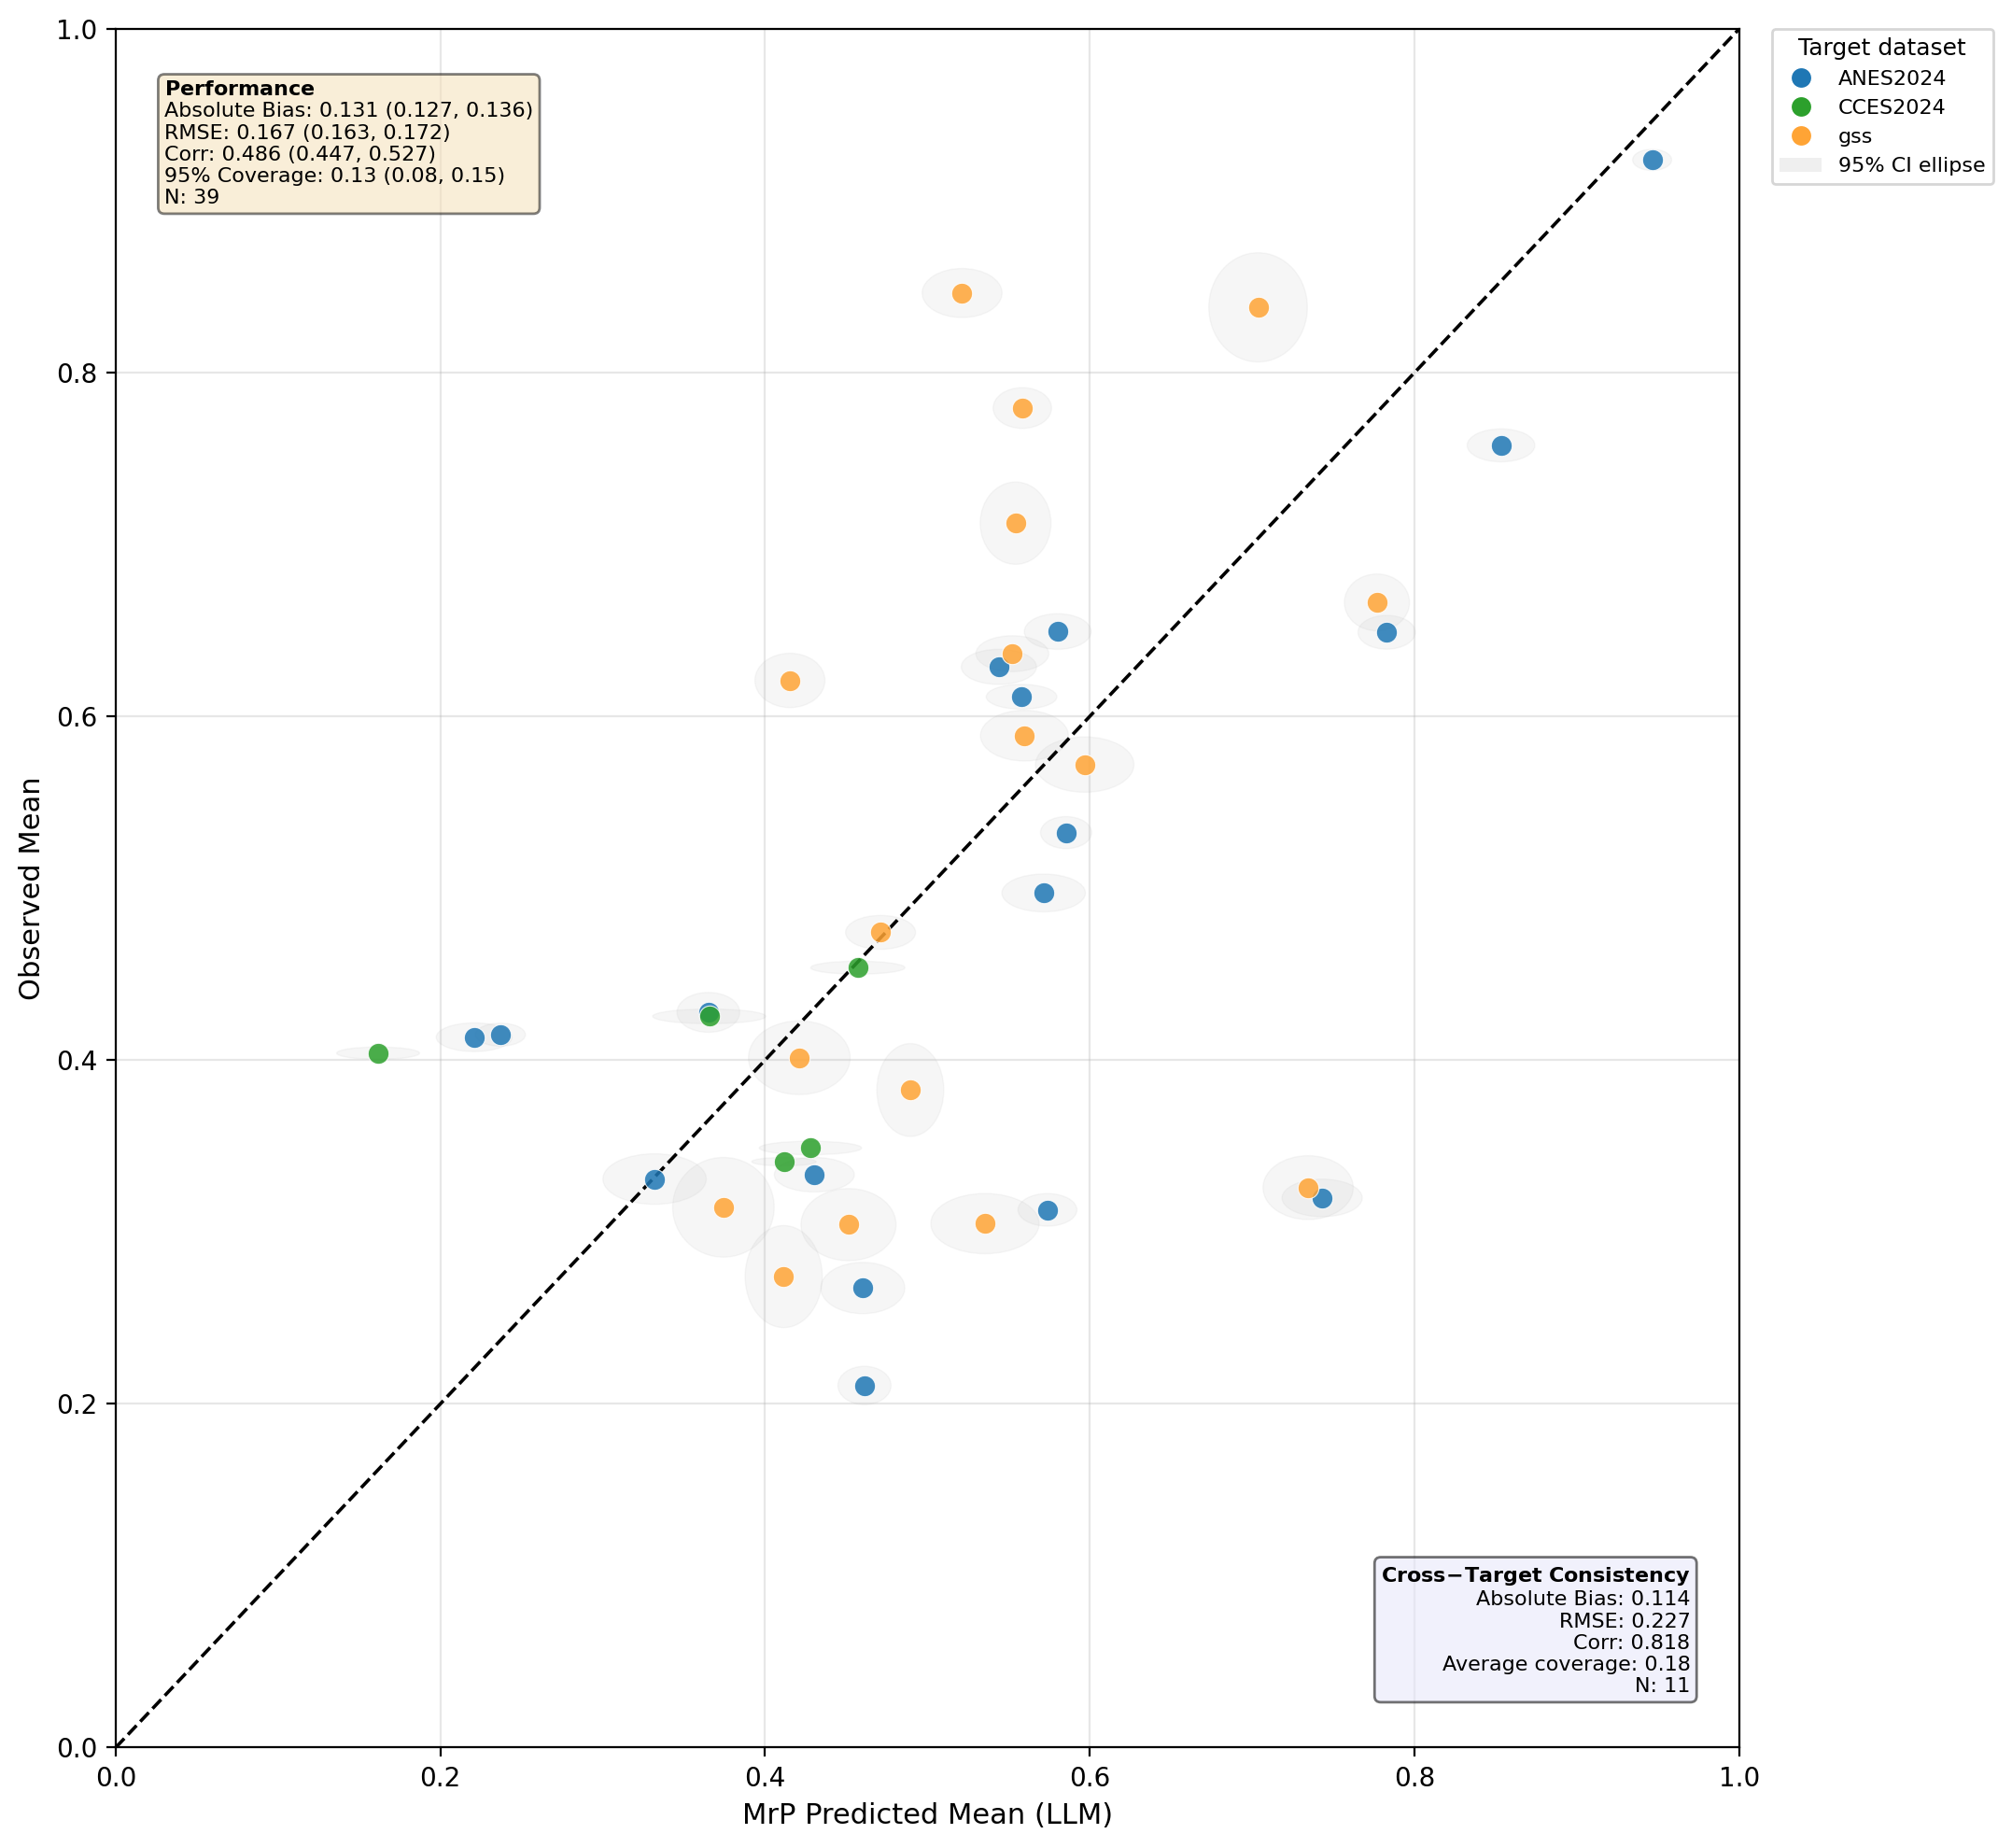

In [54]:
# show national plot
plot_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_plots')
national_path = plot_dir / 'national_single_time_vs_pooled_obs.png'
display(Markdown('**National overall plot**'))
display(Image(filename=str(national_path)))

# for only beliefs with multiple sources

In [49]:
pairwise_df['question_id'].unique()

array(['Belief_opinion_on_the_following_statement_homosexual_couples_should_have_the_right_to_marry_one_another_Symbol',
       'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol',
       'Belief_opinion_on_the_statement_because_of_past_discrimination_black_people_should_be_given_preference_in_hiring_and_promotion_Symbol',
       'Belief_opinion_on_the_statement_climate_change_is_a_major_threat_to_the_united_states_Symbol',
       'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Symbol',
       'Belief_opinion_on_the_statement_immigrants_take_jobs_away_from_people_who_were_born_in_the_usa_Symbol',
       'Belief_opinion_on_the_statement_it_is_much_better_for_everyone_involved_if_the_man_is_the_achiever_outside_the_home_and_the_woman_takes_care_of_the_home_and_family_Symbol',
       'Belief_opinion_on_what_should_be_done_with_illegal_immigrants_Symbol',
       'Belief_satisfaction_with_the_way_democracy_is_working_in_the_us_Symbol',
       'Belief_trust_in_the

In [51]:
question_ids = pairwise_df['question_id'].unique()
selected_pred_single = pred_single[pred_single['question_id'].isin(question_ids)].copy() 
selected_obs_pooled = obs_pooled[obs_pooled['question_id'].isin(question_ids)].copy()
selected_llm_draws_single = llm_draws_single[llm_draws_single['question_id'].isin(question_ids)].copy()
selected_target_boot_national = target_boot_national[target_boot_national['question_id'].isin(question_ids)].copy()

selected_plot_national_cmp = selected_pred_single[pred_cols].merge(
    selected_obs_pooled[obs_cols],
    on=['grouping_var', 'category', 'question_id', 'benchmark'],
    how='inner'
 )

selected_national_cmp_metrics = compute_metrics(
    selected_plot_national_cmp,
    llm_draws_df=selected_llm_draws_single,
    target_boot_df=selected_target_boot_national,
    y_range=1
 )

# --- Ceiling metrics for national single-time vs pooled comparison ---
# Build a minimal plot_df-like frame with has_multiple_obs for pairwise target agreement.
pairwise_input = selected_plot_national_cmp.copy()
counts = (
    pairwise_input
    .groupby(['question_id', 'grouping_var', 'category'])['benchmark']
    .nunique()
    .rename('n_obs_sources')
    .reset_index()
)
pairwise_input = pairwise_input.merge(
    counts,
    on=['question_id', 'grouping_var', 'category'],
    how='left'
)
pairwise_input['has_multiple_obs'] = pairwise_input['n_obs_sources'] > 1

pairwise_df = compute_obs_pairwise(pairwise_input)
ceiling_metrics = compute_obs_pairwise_metrics(pairwise_df, ci_level=95)



out_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_plots')
out_dir.mkdir(parents=True, exist_ok=True)
out_path = out_dir / 'national_single_time_vs_pooled_obs.png'

fig_cmp, ax_cmp = plt.subplots(1, 1, figsize=(14, 10))
plot_scatter_with_uncertainty_ellipses(
    ax_cmp,
    selected_plot_national_cmp,
    metrics=selected_national_cmp_metrics,
    ci_level=95,
    question_id=None,
    benchmark=None,
    ceiling_metrics=ceiling_metrics,
    state=None,
    national=True,
    show_legend=False,
    standardized_axis=True
)
fig_cmp.tight_layout(rect=[0, 0, 0.78, 1])
fig_cmp.savefig(out_path, dpi=200, bbox_inches='tight')
plt.close(fig_cmp)

print('Saved:', out_path)
print('National pooled vs single-time performance:', selected_national_cmp_metrics)

Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_plots/national_single_time_vs_pooled_obs.png
National pooled vs single-time performance: {'bias_mean': 0.13736751239283151, 'bias_ci': (0.1318183236963606, 0.14343728312151238), 'rmse_mean': 0.1807891894987457, 'rmse_ci': (0.17460038617232884, 0.18736020414802942), 'corr_mean': 0.4669678147939018, 'corr_ci': (0.4356013551665726, 0.527442123094297), 'coverage_mean': 0.13636363636363635, 'coverage_ci': (0.045454545454545456, 0.18181818181818182), 'n_cells': 22}


## national level time correlation analysis

In [ ]:
# build a dataframe for each unique question id, compute the spearman correlation between the pred_mean and obs_mean, in the end also give an overall correlation across all questions

records = []
for qid, grp in national_all.groupby('question_id'):
    x = grp['pred_mean'].to_numpy(dtype=float)
    y = grp['obs_mean'].to_numpy(dtype=float)
    n = len(grp)
    corr, _ = stats.spearmanr(x, y)
    records.append({
        'question_id': qid,
        'n_time_bins': n,
        'spearman_corr': corr
    })

corr_by_question = pd.DataFrame(records).sort_values('spearman_corr', ascending=False)
overall_corr, _ = stats.spearmanr(
    national_all['pred_mean'].to_numpy(dtype=float),
    national_all['obs_mean'].to_numpy(dtype=float)
 )

print('Overall Spearman correlation:', overall_corr)
corr_by_question

In [ ]:
corr_by_question['question_id'].unique()

In [ ]:
test = national_all[national_all['question_id'] == 'Belief_increase_fossil_fuel_production_Symbol']
test[['pred_mean', 'obs_mean']] 

In [ ]:
# filter only the questions with n_time_bins >= 5 to ensure more reliable correlation estimates, then sort by spearman_corr, and compute overall correlation
filtered = corr_by_question[corr_by_question['n_time_bins'] >= 5]
filtered = filtered.sort_values('spearman_corr', ascending=False)
overall_corr_filtered, _ = stats.spearmanr(
    national_all[national_all['question_id'].isin(filtered['question_id'])]['pred_mean'].to_numpy(dtype=float),
    national_all[national_all['question_id'].isin(filtered['question_id'])]['obs_mean'].to_numpy(dtype=float)
)
print('Overall Spearman correlation (filtered):', overall_corr_filtered)
filtered

In [ ]:
title_mapper['Target Quality'].value_counts()

# plot the national plot and all belief plots with only belief questions that has target quality = good

In [ ]:
# plot the national plot and all belief plots with only belief questions that has target quality = good

good_qids = (
    title_mapper.loc[
        title_mapper['Target Quality'].astype(str).str.lower() == 'good',
        'cleaned_feature'
    ]
    .dropna()
    .astype(str)
    .unique()
 )

good_plot_df = standardized_plot_df[
    standardized_plot_df['question_id'].astype(str).isin(good_qids)
].copy()
if good_plot_df.empty:
    raise ValueError('No rows found for Target Quality == good.')

key_cols = ['grouping_var', 'category', 'question_id', 'benchmark']

# All-belief plots (demographics + state).
demo_good = good_plot_df[~good_plot_df['grouping_var'].isin(['state', 'time_window_bin'])].copy()
state_good = good_plot_df[good_plot_df['grouping_var'] == 'state'].copy()

demo_keys = demo_good[key_cols].drop_duplicates()
state_keys = state_good[key_cols].drop_duplicates()

llm_draws_demo = llm_draws_std.merge(demo_keys, on=key_cols, how='inner')
target_boot_demo = target_boot_std.merge(demo_keys, on=key_cols, how='inner')
llm_draws_state = llm_draws_std.merge(state_keys, on=key_cols, how='inner')
target_boot_state = target_boot_std.merge(state_keys, on=key_cols, how='inner')

demo_perf = compute_metrics(
    demo_good,
    llm_draws_df=llm_draws_demo,
    target_boot_df=target_boot_demo,
    y_range = 1
 )
state_perf = compute_metrics(
    state_good,
    llm_draws_df=llm_draws_state,
    target_boot_df=target_boot_state,
    y_range = 1
 )

demo_ceiling_pairwise = compute_obs_pairwise(demo_good)
demo_ceiling = compute_obs_pairwise_metrics(demo_ceiling_pairwise, ci_level=95)

out_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_belief_plots')
out_dir.mkdir(parents=True, exist_ok=True)
demo_out = out_dir / 'all_beliefs_demographics_good.png'
state_out = out_dir / 'all_beliefs_state_good.png'

fig_demo, ax_demo = plt.subplots(1, 1, figsize=(14, 10))
plot_scatter_with_uncertainty_ellipses(
    ax_demo,
    demo_good,
    metrics=demo_perf,
    ci_level=95,
    question_id=None,
    benchmark=None,
    ceiling_metrics=demo_ceiling,
    state=False,
    standardized_axis=True
 )
fig_demo.tight_layout(rect=[0, 0, 0.78, 1])
fig_demo.savefig(demo_out, dpi=200, bbox_inches='tight')
plt.close(fig_demo)

fig_state, ax_state = plt.subplots(1, 1, figsize=(14, 10))
plot_scatter_with_uncertainty_ellipses(
    ax_state,
    state_good,
    metrics=state_perf,
    ci_level=95,
    question_id=None,
    benchmark=None,
    ceiling_metrics=None,
    state=True,
    standardized_axis=True
 )
fig_state.tight_layout(rect=[0, 0, 0.78, 1])
fig_state.savefig(state_out, dpi=200, bbox_inches='tight')
plt.close(fig_state)

print('Saved:', demo_out)
print('Saved:', state_out)

# National plot 
national_good = good_plot_df[good_plot_df['grouping_var'] == 'time_window_bin'].copy()
if national_good.empty:
    raise ValueError('No national time_window_bin rows found for Target Quality == good.')

national_keys = national_good[key_cols].drop_duplicates()
llm_draws_national = llm_draws_std.merge(national_keys, on=key_cols, how='inner')
target_boot_national = target_boot_std.merge(national_keys, on=key_cols, how='inner')

national_perf = compute_metrics(
    national_good,
    llm_draws_df=llm_draws_national,
    target_boot_df=target_boot_national,
    y_range = 1
 )
national_ceiling_pairwise = compute_obs_pairwise(national_good)
national_ceiling = compute_obs_pairwise_metrics(national_ceiling_pairwise, ci_level=95)

out_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_plots')
out_dir.mkdir(parents=True, exist_ok=True)
national_out = out_dir / 'national_time_window_scatter_good.png'

fig_nat, ax_nat = plt.subplots(1, 1, figsize=(14, 10))
plot_scatter_with_uncertainty_ellipses(
    ax_nat,
    national_good,
    metrics=national_perf,
    ci_level=95,
    question_id=None,
    benchmark=None,
    ceiling_metrics=national_ceiling,
    state=None,
    standardized_axis=True
 )
fig_nat.tight_layout(rect=[0, 0, 0.78, 1])
fig_nat.savefig(national_out, dpi=200, bbox_inches='tight')
plt.close(fig_nat)

print('Saved:', national_out)

In [ ]:
good_qids

In [ ]:
# show good-only plots
all_plot_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_belief_plots')
nat_plot_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_plots')

demo_good_path = all_plot_dir / 'all_beliefs_demographics_good.png'
state_good_path = all_plot_dir / 'all_beliefs_state_good.png'
national_good_path = nat_plot_dir / 'national_time_window_scatter_good.png'

display(Markdown('**All beliefs (good only): demographics**'))
display(Image(filename=str(demo_good_path)))

display(Markdown('**All beliefs (good only): state**'))
display(Image(filename=str(state_good_path)))

display(Markdown('**National time window (good only)**'))
display(Image(filename=str(national_good_path)))

In [ ]:
# correlatioin_by_question for good-only questions

good_qids = (
    title_mapper.loc[
        title_mapper['Target Quality'].astype(str).str.lower() == 'good',
        'cleaned_feature'
    ]
    .dropna()
    .astype(str)
    .unique()
 )

national_good = national_all[
    national_all['question_id'].astype(str).isin(good_qids)
].copy()
if national_good.empty:
    raise ValueError('No national rows found for Target Quality == good.')

records = []
for qid, grp in national_good.groupby('question_id'):
    x = grp['pred_mean'].to_numpy(dtype=float)
    y = grp['obs_mean'].to_numpy(dtype=float)
    n = len(grp)
    corr, _ = stats.spearmanr(x, y)
    records.append({
        'question_id': qid,
        'n_time_bins': n,
        'spearman_corr': corr
    })

corr_by_question = pd.DataFrame(records).sort_values('spearman_corr', ascending=False)
overall_corr, _ = stats.spearmanr(
    national_good['pred_mean'].to_numpy(dtype=float),
    national_good['obs_mean'].to_numpy(dtype=float)
 )

print('Overall Spearman correlation (good only):', overall_corr)
corr_by_question

In [ ]:
# test: plot national time window for one belief question
def plot_national_time_window_single_question(
    question_id,
    plot_df_input,
    llm_draws_input,
    target_boot_input,
    output_dir=None,
    standardized_axis=True,
    save=False
 ):
    work = plot_df_input[
        (plot_df_input['grouping_var'] == 'time_window_bin')
        & (plot_df_input['question_id'].astype(str) == str(question_id))
    ].copy()
    if work.empty:
        raise ValueError(f'No national time_window_bin rows for question_id={question_id}.')

    key_cols = ['grouping_var', 'category', 'question_id', 'benchmark']
    keys = work[key_cols].drop_duplicates()
    llm_draws_sub = llm_draws_input.merge(keys, on=key_cols, how='inner')
    target_boot_sub = target_boot_input.merge(keys, on=key_cols, how='inner')

    metrics = compute_metrics(
        work,
        llm_draws_df=llm_draws_sub,
        target_boot_df=target_boot_sub,
        y_range = 1
    )
    ceiling_pairwise = compute_obs_pairwise(work)
    ceiling_metrics = compute_obs_pairwise_metrics(ceiling_pairwise, ci_level=95)

    fig, ax = plt.subplots(1, 1, figsize=(14, 10))
    plot_scatter_with_uncertainty_ellipses(
        ax,
        work,
        metrics=metrics,
        ci_level=95,
        question_id=str(question_id),
        benchmark=None,
        ceiling_metrics=ceiling_metrics,
        state=None,
        standardized_axis=standardized_axis
    )
    fig.tight_layout(rect=[0, 0, 0.78, 1])

    out_path = None
    if save:
        out_dir = Path(output_dir)
        out_dir.mkdir(parents=True, exist_ok=True)
        safe_qid = str(question_id).removesuffix('_Symbol')
        out_path = out_dir / f'{safe_qid}_national_time_window.png'
        fig.savefig(out_path, dpi=200, bbox_inches='tight')
        print('Saved:', out_path)

    return fig, ax, metrics, ceiling_metrics, out_path

In [ ]:
fig, ax, metrics, ceiling_metrics, out_path = plot_national_time_window_single_question(
    question_id='Belief_opinion_on_whether_divorce_in_the_usa_should_be_easier_or_more_difficult_to_obtain_than_it_is_Symbol',
    plot_df_input=standardized_plot_df,
    llm_draws_input=llm_draws_std,
    target_boot_input=target_boot_std,
    standardized_axis=True,
    save=False
 )

# put the result in overleaf
national one folder
sub-demographic second folder
state fodler
 each folder national + per_belief plots
appendix
    select time window (table of speculation score)
    screenshot of to decide what LLMs to use in the end(result or observations)

In [ ]:
# duplicate existing plots into the new folder structure 
import shutil

root_generated_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data')
all_beliefs_dir = root_generated_dir / 'all_belief_plots'
state_dir = root_generated_dir / 'state'
demo_dir = root_generated_dir / 'demographics'

state_dir.mkdir(parents=True, exist_ok=True)
demo_dir.mkdir(parents=True, exist_ok=True)

def copy_if_exists(src_path, dest_path):
    if not src_path.exists():
        print(f'Warning: source path {src_path} does not exist; skipping copy to {dest_path}')
        return False
    try:
        if src_path.resolve() == dest_path.resolve():
            return False
    except FileNotFoundError:
        pass
    dest_path.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src_path, dest_path)
    return True

prefix_map = (
    belief_prefix_df[['belief_name', 'most_common_prefix']]
    .dropna()
    .drop_duplicates()
    .set_index('belief_name')['most_common_prefix']
    .to_dict()
 )

# Copy per-belief plots into each belief's plot subfolder and the root state/demographics folders.
questions = plot_df['question_id'].dropna().astype(str).unique()
for qid in questions:
    safe_qid = str(qid).removesuffix('_Symbol')
    belief_dir = root_generated_dir / qid
    belief_plot_dir = belief_dir / 'plot'
    belief_plot_dir.mkdir(parents=True, exist_ok=True)

    src_demo = belief_plot_dir / f'{safe_qid}_demographics.png'
    src_state = belief_plot_dir / f'{safe_qid}_state.png'

    # Ensure the plot subfolder holds the plots (duplicate from existing path).
    copy_if_exists(src_demo, belief_plot_dir / src_demo.name)
    copy_if_exists(src_state, belief_plot_dir / src_state.name)

    prefix = prefix_map.get(qid)
    if not prefix:
        raise KeyError(f'Missing prefix for {qid}')

    demo_name = f"{prefix}_demographics.png"
    state_name = f"{prefix}_state.png"
    copy_if_exists(src_demo, demo_dir / demo_name)
    copy_if_exists(src_state, state_dir / state_name)

# Copy pooled plots into root-level folders.
copy_if_exists(all_beliefs_dir / 'all_beliefs_demographics.png', demo_dir / 'all_beliefs_demographics.png')
copy_if_exists(all_beliefs_dir / 'all_beliefs_state.png', state_dir / 'all_beliefs_state.png')

print('Done: duplicated plots into state/ and demographics/ folders.')